# Packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import pyarrow
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import scipy.stats as stats
import plotly.express as px
from datetime import date

# Read data

In [3]:
features_df = pd.read_parquet(r"..\data\features.parquet", engine="pyarrow")

In [19]:
features_df

,timestamp,energy,kurtosis,frecuency_index,entropy,frequency_index,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean
0,2022-01-01 00:05:00,7.074324,0.633977,None,6743.988806,-0.005959,NaN,NaN,NaN,NaN
1,2022-01-01 00:10:00,7.020175,0.632777,None,7043.316623,-0.109812,NaN,NaN,NaN,NaN
2,2022-01-01 00:15:00,7.011306,0.751629,None,7175.473832,0.032564,NaN,NaN,NaN,NaN
3,2022-01-01 00:20:00,7.010472,0.750180,None,7186.277967,0.065660,NaN,NaN,NaN,NaN
4,2022-01-01 00:25:00,6.986411,0.732571,None,7290.097859,-0.179743,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
244232,2024-04-30 23:35:00,8.643414,2.048395,None,1880.653717,0.013671,8.475240,1.661013,0.164519,2422.352334
244233,2024-04-30 23:40:00,8.641434,2.054361,None,1901.904995,0.043806,8.499053,1.732388,0.143333,2391.615290
244234,2024-04-30 23:45:00,8.363330,1.555841,None,2333.147244,0.213128,8.420484,1.676854,0.156674,2462.867215
244235,2024-04-30 23:50:00,8.399109,1.484056,None,2234.924698,0.218329,8.336336,1.595239,0.172988,2519.611226


In [4]:
# Mobile mean with a window of one hour
hours = 1
# Apply filters to the time series of the features
features_df = features_df[(features_df['energy']>=0)&(features_df['kurtosis']<2500)&(features_df['frequency_index']>=-3)&(features_df['entropy']>=0)&(features_df['entropy']<15000)]
# Calculate moving average for all features
# Apply logarithmic transformation to energy and kurtosis variables
features_df['energy_mobile_mean'] = np.log10(features_df['energy'].rolling(window=11*hours, center=False).mean())
features_df['kurtosis_mobile_mean'] = np.log10(features_df['kurtosis'].rolling(window=11*hours, center=False).mean())
features_df['frequency_index_mobile_mean'] = features_df['frequency_index'].rolling(window=11*hours, center=False).mean()
features_df['entropy_mobile_mean'] = features_df['entropy'].rolling(window=11*hours, center=False).mean()
features_df['energy'] = np.log10(features_df['energy'])
features_df['kurtosis'] = np.log10(features_df['kurtosis'])

### Training Set

In [5]:
# Select just one month of data
features_df_1_month = features_df[features_df['timestamp']<"2022-02-01"]
# Filter the first eleven observations with NAs values
features_df_1_month = features_df_1_month.dropna(subset=['energy_mobile_mean'])

In [6]:
# Take descriptive variables
variables = ["energy_mobile_mean",	"kurtosis_mobile_mean", "frequency_index_mobile_mean", "entropy_mobile_mean"]
X = features_df_1_month[["energy_mobile_mean",	"kurtosis_mobile_mean",	
                         "frequency_index_mobile_mean", "entropy_mobile_mean"]].to_numpy()


##### Preproccesing

In [7]:
# Scale variables
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Dimensionality Reduction:
PCA

In [8]:
# Create a PCA object and train it
pca = PCA(n_components=3).fit(X)
# Transform the data to the new reducted space
Z = pca.transform(X)

### Clustering

In [9]:
km_model = KMeans(n_clusters=3, random_state=9972, n_init=10).fit(Z)

In [10]:
# Create a dataframe with the clustering data
clustering_data = features_df_1_month[
    [   
        'timestamp',
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
].copy()
clustering_data['labels'] = km_model.labels_

### Groups Distribution

In [11]:
clustering_data[['labels', 'energy_mobile_mean']].groupby('labels').count()

,energy_mobile_mean
labels,
0,2775
1,4649
2,1459


### Results Original Data

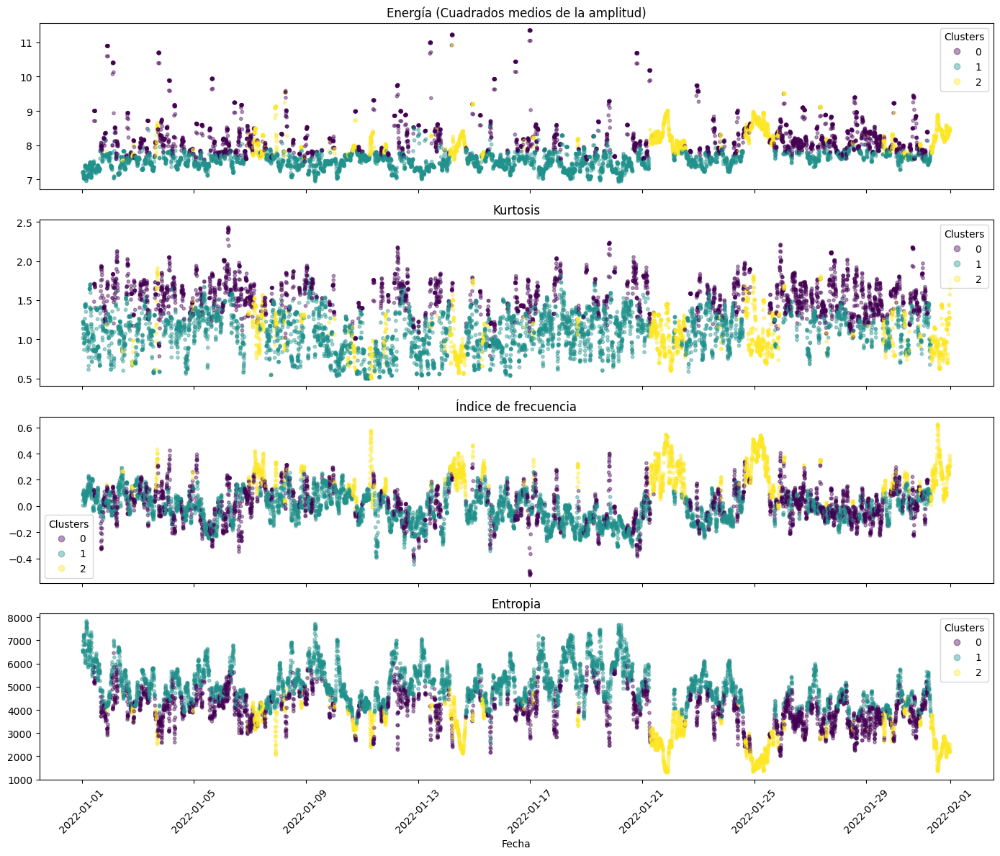

In [12]:
# Generate the plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(clustering_data['timestamp'], clustering_data['energy_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(clustering_data['timestamp'], clustering_data['kurtosis_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(clustering_data['timestamp'], clustering_data['frequency_index_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(clustering_data['timestamp'], clustering_data['entropy_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")

plt.xticks(rotation=45)
plt.tight_layout()

### Identify Outliers

In [13]:
distances = km_model.transform(Z)
clustering_data['distance_to_centroid'] = [distances[i, label] for i, label in enumerate(km_model.labels_)]

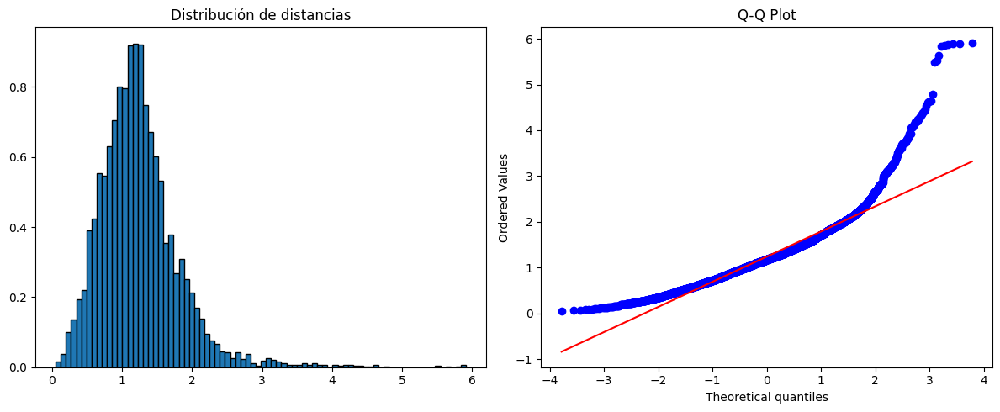

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(clustering_data['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(clustering_data['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [15]:
clustering_data

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,1.206069
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,1.238339
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,1.376893
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,1.392648
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,1.389105
...,...,...,...,...,...,...,...
8892,2022-01-31 23:35:00,8.471704,1.573340,0.347591,2194.681709,2,1.797239
8893,2022-01-31 23:40:00,8.512201,1.760099,0.385613,2178.716875,2,2.380102
8894,2022-01-31 23:45:00,8.474237,1.714692,0.360933,2273.282381,2,2.177012
8895,2022-01-31 23:50:00,8.432990,1.659252,0.330689,2379.334500,2,1.940076


In [16]:
# Clasificamos los valores observados como típicos y atípicos
clustering_data['outliers'] = clustering_data['distance_to_centroid'] > 5



# Cálculo de cuartiles y cota superior de valores
#Q1 = clustering_data['distance_to_centroid'].quantile(0.25)
#Q3 = clustering_data['distance_to_centroid'].quantile(0.75)
#IQR = Q3 - Q1
#upper_increment = Q3 + 1.5*IQR

#clustering_data['outliers'] = clustering_data['distance_to_centroid'] > upper_increment


#print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
#print(f"Cota superior (Q3 + 1.5*IQR): {upper_increment:.3f}")
#print(f"Outliers: {clustering_data['outliers'].sum()} ({100*clustering_data['outliers'].mean():.2f}%)")

#clustering_data['outliers'] = clustering_data['distance_to_centroid'] > upper_increment

# Outliers defined as the distances above the 995th percentile
#PERCENTILE = 0.995
#upper_increment = clustering_data['distance_to_centroid'].quantile(PERCENTILE)

#print(f"Cota superior (percentil {PERCENTILE}): {upper_increment:.3f}")

#clustering_data['outliers'] = clustering_data['distance_to_centroid'] > upper_increment
#print(f"Outliers: {clustering_data['outliers'].sum()} ({100*clustering_data['outliers'].mean():.2f}%)")


In [17]:
# 
sum(clustering_data['outliers'])

9

### Next Months Forecast

In [18]:
features_df_pred = features_df[(features_df['timestamp']<"2025-02-02") & (features_df['timestamp']>="2022-02-01")]

clustering_data_pred = features_df_pred[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

In [19]:
# Scale variables
X_pred = scaler.transform(clustering_data_pred)
# Transform the data to the new reducted space
Z_pred = pca.transform(X_pred)

c:\Users\LENOVO\OneDrive\Documentos\Estancia de Investigación\Estancia_Maestría\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [20]:
# Predict clusters for new data using the same centroids
labels_pred = km_model.predict(Z_pred)

### Outliers in New Data

In [21]:
# Add labels and timestamp to the new dataframe
clustering_data_pred['timestamp'] = features_df_pred['timestamp']
clustering_data_pred['labels'] = labels_pred

distances_pred = km_model.transform(Z_pred)



clustering_data_pred['distance_to_centroid'] = [distances_pred[i, label] for i, label in enumerate(labels_pred)]

clustering_data_pred['outliers'] = clustering_data_pred['distance_to_centroid'] > 5


#print(f"Cota superior (percentil {PERCENTILE}): {upper_increment:.3f}")
#print(f"Cota superior (Tukey Outlier): {upper_increment:.3f}")
#clustering_data_pred['outliers'] = clustering_data_pred['distance_to_centroid'] > upper_increment
#print(f"Outliers: {clustering_data_pred['outliers'].sum()} ({100*clustering_data_pred['outliers'].mean():.2f}%)")





C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\3063957306.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clustering_data_pred['timestamp'] = features_df_pred['timestamp']
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\3063957306.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clustering_data_pred['labels'] = labels_pred
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\3063957306.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .lo

In [22]:
# Concat the test data
clustering_data_all = pd.concat([clustering_data, clustering_data_pred], axis = 0)

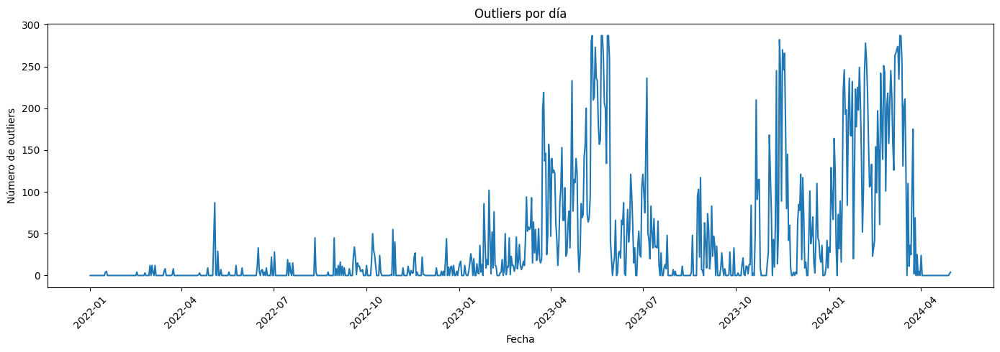

In [23]:
clustering_data_all['date'] = pd.to_datetime(clustering_data_all['timestamp']).dt.date

total_by_day = clustering_data_all.groupby('date').size()
outliers_by_day_0 = (clustering_data_all[clustering_data_all['outliers'] == True]
                   .groupby('date')
                   .size())
# Reindex con todos los días, llenando con 0
outliers_by_day_0 = outliers_by_day_0.reindex(total_by_day.index, fill_value=0)

outliers_by_day_0 = outliers_by_day_0.reset_index()
outliers_by_day_0.columns = ['date', 'outliers']
outliers_by_day_0['total'] = total_by_day.values

plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day_0['date'], outliers_by_day_0['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Graficar el RSAM 
## Graficar valores de la segunda derivada (revisar puntos de inflexión)
## Primera derivada entre valores del día anterior o promedio de los últimos n días

In [ ]:
# outliers_by_day_0.to_csv(r'..\data\outliers\outliers_pred.csv', index = False)

### Model retraining

In [24]:
window_days = 84

outliers_by_day_0['mean_window'] = outliers_by_day_0['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_0['std_window'] = outliers_by_day_0['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_0['threshold'] = outliers_by_day_0['mean_window'] + 3*outliers_by_day_0['std_window']
outliers_by_day_0['retrain'] = outliers_by_day_0['outliers'] > outliers_by_day_0['threshold']

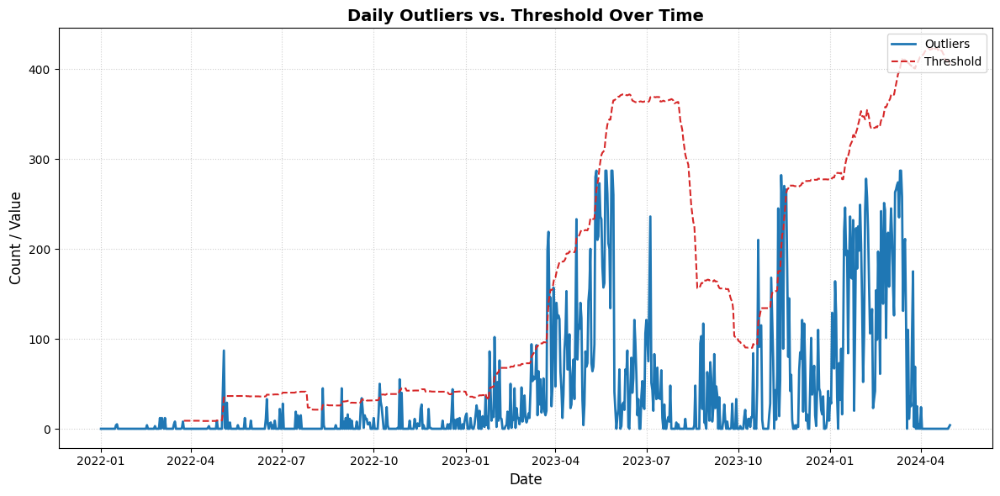

In [25]:
plt.figure(figsize=(12, 6))

# Plot the series
plt.plot(
    outliers_by_day_0['date'],
    outliers_by_day_0["outliers"],
    label="Outliers",
    color="#1f77b4",
    linewidth=2,
)
plt.plot(
    outliers_by_day_0['date'],
    outliers_by_day_0["threshold"],
    label="Threshold",
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
)

# Formatting
plt.title("Daily Outliers vs. Threshold Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()

plt.show()

In [26]:
outliers_by_day_0[outliers_by_day_0['retrain'] == True]

,date,outliers,total,mean_window,std_window,threshold,retrain
121,2022-05-03,44,287,1.488095,5.445224,17.823766,True
122,2022-05-04,87,287,2.523810,10.799907,34.923529,True
221,2022-08-11,45,287,2.904762,7.802717,26.312912,True
240,2022-08-30,45,287,3.285714,8.975967,30.213616,True
260,2022-09-19,34,287,3.833333,9.415232,32.079028,True
278,2022-10-07,50,287,4.869048,10.382770,36.017359,True
298,2022-10-27,55,287,6.250000,12.237484,42.962453,True
348,2022-12-19,44,287,5.857143,11.782305,41.204059,True
385,2023-01-25,86,287,6.392857,12.451368,43.746962,True
390,2023-01-30,102,287,8.607143,16.625585,58.483897,True


#### Create new groups for the outliers before the cutday

In [27]:
buffer = clustering_data_all[(clustering_data_all['timestamp'] < "2022-05-04") & clustering_data_all['outliers']].copy()[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

# Scale variables
X_buffer = scaler.transform(buffer)
# Transform the data to the new reducted space
Z_buffer = pca.transform(X_buffer)

print(f"Outliers en buffer: {len(buffer)}")

Outliers en buffer: 134


c:\Users\LENOVO\OneDrive\Documentos\Estancia de Investigación\Estancia_Maestría\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [28]:
# Trata con differentes valores para k
inertia = []
silh = []
k_s = np.arange(2, 10)
for k in k_s:
  km_model_aux = KMeans(n_clusters=k).fit(Z_buffer)
  inertia.append(km_model_aux.inertia_)
  silh.append(silhouette_score(Z_buffer, km_model_aux.labels_))

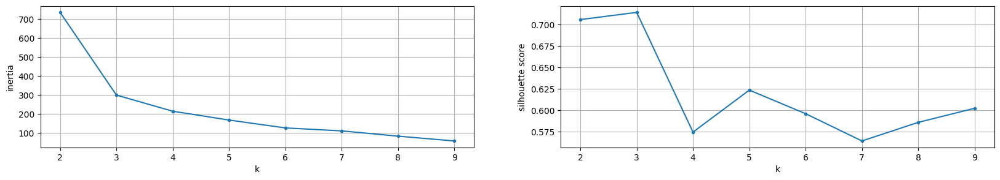

In [29]:
# Plot results
plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s, inertia, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s, silh, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [30]:
km_model_buffer = KMeans(n_clusters=3, random_state=9972, n_init=10).fit(Z_buffer)

len(km_model_buffer.cluster_centers_)

3

In [31]:
# Create a dataframe with the clustering data
clustering_data_buffer = pd.DataFrame(Z_buffer, columns= ['PC1', 'PC2', 'PC3'])
clustering_data_buffer['labels'] = km_model_buffer.labels_
# Create a dataframe with the clustering data


In [32]:
clustering_data_buffer[['labels','PC1']].groupby('labels').count()

,PC1
labels,
0,40
1,65
2,29


In [33]:
MIN_MIEMBROS = 20   # ajusta según lo que viste arriba

n_original = len(km_model.cluster_centers_)
promover = []   # índices del buffer que sí se promueven

for k in range(km_model_buffer.n_clusters):
    n = (km_model_buffer.labels_ == k).sum()
    if n >= MIN_MIEMBROS:
        promover.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original + len(promover) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

✓ Buffer 0 (40 miembros) → será Cluster 3
✓ Buffer 1 (65 miembros) → será Cluster 4
✓ Buffer 2 (29 miembros) → será Cluster 5


In [34]:
mapping = {}   # {label_buffer: label_global}
for i, k in enumerate(promover):
    mapping[k] = n_original + i

print("Mapeo buffer → global:", mapping)

Mapeo buffer → global: {0: 3, 1: 4, 2: 5}


In [35]:
nuevos_centroides = km_model_buffer.cluster_centers_[promover]

centroides_expandidos = np.vstack([
    km_model.cluster_centers_,
    nuevos_centroides
])

print(f"Centroides: {n_original} → {len(centroides_expandidos)}")

Centroides: 3 → 6


In [36]:
buffer_labels_globales = np.array([
    mapping.get(lbl, -1) for lbl in km_model_buffer.labels_
])

buffer['labels_nuevo'] = buffer_labels_globales

print(pd.Series(buffer_labels_globales).value_counts().sort_index())

3    40
4    65
5    29
Name: count, dtype: int64


#### Changing the labels

In [37]:
past_data_df = clustering_data_all[(clustering_data_all['timestamp'] < "2022-05-04")]

In [38]:
past_data_df

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid,outliers,date
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,1.206069,False,2022-01-01
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,1.238339,False,2022-01-01
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,1.376893,False,2022-01-01
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,1.392648,False,2022-01-01
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,1.389105,False,2022-01-01
...,...,...,...,...,...,...,...,...,...
35296,2022-05-03 23:35:00,10.305004,0.530118,1.160464,344.608118,2,6.765748,True,2022-05-03
35297,2022-05-03 23:40:00,10.240232,0.533679,1.151212,361.671388,2,6.680043,True,2022-05-03
35298,2022-05-03 23:45:00,10.156998,0.533571,1.136936,384.076035,2,6.561054,True,2022-05-03
35299,2022-05-03 23:50:00,10.084959,0.529283,1.124651,406.264841,2,6.459693,True,2022-05-03


In [39]:
# Initialize with the original labels
past_data_df['labels_final'] = past_data_df['labels']

# Overwrite only the rows of the buffer using the index
past_data_df.loc[buffer.index, 'labels_final'] = buffer['labels_nuevo']

# Tag the points that still are outliers
past_data_df['outliers_final'] = past_data_df['labels_final'] == -1

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\1031854091.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['labels_final'] = past_data_df['labels']
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\1031854091.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['outliers_final'] = past_data_df['labels_final'] == -1


In [40]:
past_data_df

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid,outliers,date,labels_final,outliers_final
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,1.206069,False,2022-01-01,1,False
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,1.238339,False,2022-01-01,1,False
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,1.376893,False,2022-01-01,1,False
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,1.392648,False,2022-01-01,1,False
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,1.389105,False,2022-01-01,1,False
...,...,...,...,...,...,...,...,...,...,...,...
35296,2022-05-03 23:35:00,10.305004,0.530118,1.160464,344.608118,2,6.765748,True,2022-05-03,3,False
35297,2022-05-03 23:40:00,10.240232,0.533679,1.151212,361.671388,2,6.680043,True,2022-05-03,3,False
35298,2022-05-03 23:45:00,10.156998,0.533571,1.136936,384.076035,2,6.561054,True,2022-05-03,3,False
35299,2022-05-03 23:50:00,10.084959,0.529283,1.124651,406.264841,2,6.459693,True,2022-05-03,3,False


In [41]:
n_before = past_data_df['outliers'].sum()
n_after = past_data_df['outliers_final'].sum()

print(f"Outliers antes:   {n_before}")
print(f"Outliers después: {n_after}")
print(f"Absorbidos:       {n_before - n_after}\n")

print(past_data_df['labels_final'].value_counts().sort_index())

Outliers antes:   134
Outliers después: 0
Absorbidos:       134

labels_final
0    11218
1    11997
2    10780
3       40
4       65
5       29
Name: count, dtype: int64


In [42]:
from sklearn.metrics import pairwise_distances


X_past = scaler.transform(past_data_df[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
].to_numpy())
Z_past = pca.transform(X_past)

dist_past = pairwise_distances(Z_past, centroides_expandidos)

# Same rule used for post_df: closest centroid among all the final ones
past_data_df['labels_new'] = dist_past.argmin(axis=1)
past_data_df['distance_expanded'] = dist_past.min(axis=1)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\3196513410.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['labels_new'] = dist_past.argmin(axis=1)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\3196513410.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['distance_expanded'] = dist_past.min(axis=1)


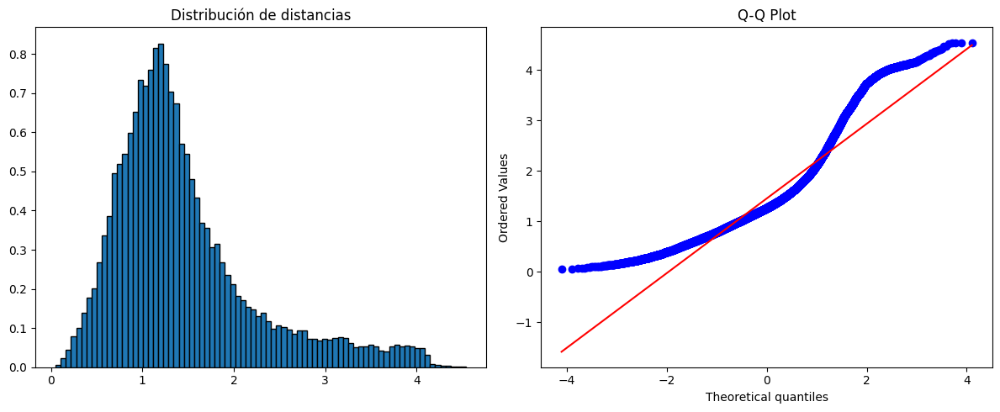

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(past_data_df['distance_expanded'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(past_data_df['distance_expanded'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [44]:
past_data_df['outliers'] = past_data_df['distance_expanded'] > 5
sum(past_data_df['outliers'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\2661970685.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['outliers'] = past_data_df['distance_expanded'] > 5


0

In [46]:


# Reference bound: percentile of the past distances
#upper_reference = past_data_df['distance_expanded'].quantile(PERCENTILE)

#print(f"Cota de referencia (percentil {PERCENTILE}): {upper_reference:.3f}")
#print(f"Outliers en el pasado: {(past_data_df['distance_expanded'] > upper_reference).sum()}")


# Cálculo de cuartiles y cota superior de valores
Q1 = past_data_df['distance_expanded'].quantile(0.25)
Q3 = past_data_df['distance_expanded'].quantile(0.75)
IQR = Q3 - Q1
upper_increment = Q3 + 1.5*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + 1.5*IQR): {upper_increment:.3f}")
print(f"Outliers: {past_data_df['outliers'].sum()} ({100*past_data_df['outliers'].mean():.2f}%)")

past_data_df['outliers'] = past_data_df['distance_expanded'] > upper_increment



Q1: 0.939 | Q3: 1.739 | IQR: 0.801
Cota superior (Q3 + 1.5*IQR): 2.940
Outliers: 2383 (6.98%)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18748\2953269469.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  past_data_df['outliers'] = past_data_df['distance_expanded'] > upper_increment


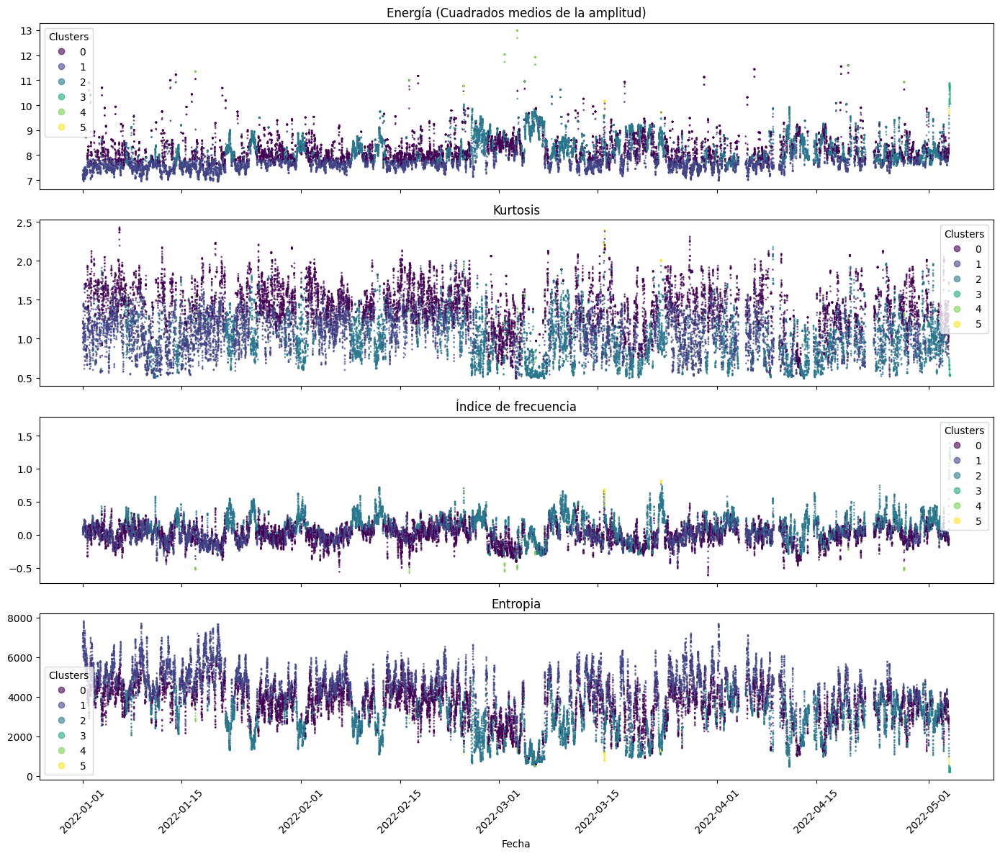

In [47]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(past_data_df['timestamp'], past_data_df['energy_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(past_data_df['timestamp'], past_data_df['kurtosis_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(past_data_df['timestamp'], past_data_df['frequency_index_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(past_data_df['timestamp'], past_data_df['entropy_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")



plt.xticks(rotation=45)
plt.tight_layout()

#### Retrain only for outliers

Apply the final model (original 3 centroids + 3 promoted from the buffer) to **all** the data after the cut day, check the distances and find the new outliers.

In [48]:

# Same cut as past_data_df (< "2022-05-04"), so there is no overlap
cut_day_1 = "2022-05-04"
feature_cols = [
    'energy_mobile_mean',
    'kurtosis_mobile_mean',
    'frequency_index_mobile_mean',
    'entropy_mobile_mean'
]

post_df = clustering_data_all[clustering_data_all['timestamp'] >= cut_day_1][['timestamp'] + feature_cols].copy()

# Scale + PCA with the ORIGINAL scaler and pca
X_post = scaler.transform(post_df[feature_cols].to_numpy())
Z_post = pca.transform(X_post)

print(f"Observations after {cut_day_1}: {len(post_df)}")

Observations after 2022-05-04: 205886


In [50]:
# Distance to ALL the final centroids (original + promoted), keep the closest one
dist_post = pairwise_distances(Z_post, centroides_expandidos)

post_df['labels'] = dist_post.argmin(axis=1)
post_df['distance_to_centroid'] = dist_post.min(axis=1)
post_df['outliers'] = post_df['distance_to_centroid'] > upper_increment

print(post_df['labels'].value_counts().sort_index())
print(f"\nOutliers (distance > 5): {post_df['outliers'].sum()}")



labels
0    69066
1    13309
2    52739
3      737
4    68524
5     1511
Name: count, dtype: int64

Outliers (distance > 5): 40567


In [51]:
# Distance to ALL the final centroids (original + promoted), keep the closest one
dist_post = pairwise_distances(Z_post, centroides_expandidos)

post_df['labels'] = dist_post.argmin(axis=1)
post_df['distance_to_centroid'] = dist_post.min(axis=1)
#post_df['outliers'] = post_df['distance_to_centroid'] > 5

print(post_df['labels'].value_counts().sort_index())
#print(f"\nOutliers (distance > 5): {post_df['outliers'].sum()}")


# Cálculo de cuartiles y cota superior de valores
#Q1 = post_df['distance_to_centroid'].quantile(0.25)
#Q3 = post_df['distance_to_centroid'].quantile(0.75)
#IQR = Q3 - Q1
#upper_increment = Q3 + 1.5*IQR

#print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
#print(f"Cota superior (Q3 + 3*IQR): {upper_increment:.3f}")

# Redefinimos los outliers con la nueva cota
post_df['outliers'] = post_df['distance_to_centroid'] > upper_increment
print(f"Outliers: {post_df['outliers'].sum()} ({100*post_df['outliers'].mean():.2f}%)")


# Outliers defined as the distances above the 99th percentile
#PERCENTILE = 0.99
#upper_increment = post_df['distance_to_centroid'].quantile(PERCENTILE)

#print(f"Cota superior (percentil {PERCENTILE}): {upper_increment:.3f}")

#post_df['outliers'] = post_df['distance_to_centroid'] > upper_increment
#print(f"Outliers: {post_df['outliers'].sum()} ({100*post_df['outliers'].mean():.2f}%)")

labels
0    69066
1    13309
2    52739
3      737
4    68524
5     1511
Name: count, dtype: int64
Outliers: 40567 (19.70%)


In [ ]:
# dist_post = pairwise_distances(Z_post, centroides_expandidos)

# post_df['labels'] = dist_post.argmin(axis=1)
# post_df['distance_to_centroid'] = dist_post.min(axis=1)

# # Outliers defined as the distances above the 99th percentile
# #PERCENTILE = 0.99
# #upper_increment = post_df['distance_to_centroid'].quantile(PERCENTILE)

# print(f"Cota superior (percentil {PERCENTILE}): {upper_reference:.3f}")

# post_df['outliers'] = post_df['distance_to_centroid'] > upper_reference
# print(f"Outliers: {post_df['outliers'].sum()} ({100*post_df['outliers'].mean():.2f}%)")

Cota superior (percentil 0.995): 2.794
Outliers: 13344 (6.32%)


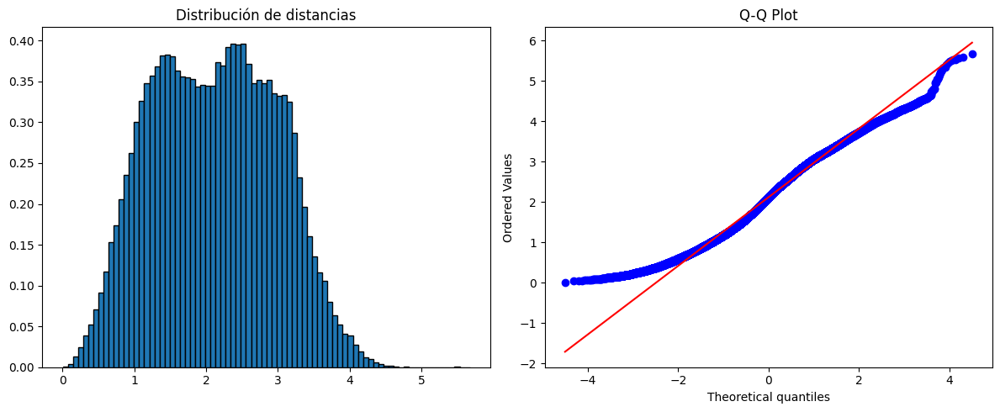

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(post_df['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(post_df['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()


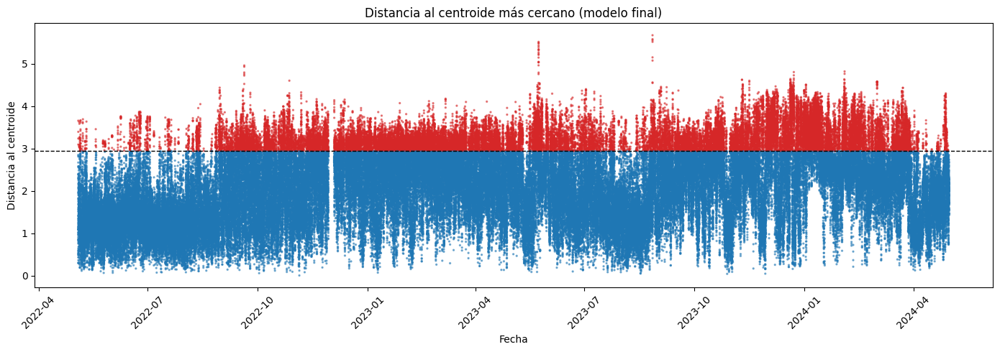

In [53]:
# Distance to the closest centroid over time
plt.figure(figsize=(14, 5))
plt.scatter(post_df['timestamp'], post_df['distance_to_centroid'],
            c=post_df['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers

In [54]:
post_df['date'] = pd.to_datetime(post_df['timestamp']).dt.date

# History of the daily outliers used to fill the rolling window before the cut day:
#  "observed": the daily counts as they were seen when the data arrived (previous model and threshold)
#  "rescored": the past re-scored with the new model and its bound
# (same switch for all the iterations)
HISTORY_MODE = "observed"

if HISTORY_MODE == "observed":
    hist_1 = outliers_by_day_0[pd.to_datetime(outliers_by_day_0['date']) < pd.Timestamp(cut_day_1)][['date', 'outliers', 'total']]
else:
    gh = past_data_df.groupby('date')['outliers']
    hist_1 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df.groupby('date')['outliers']
new_1 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_1 = pd.concat([hist_1, new_1]).reset_index(drop=True)
outliers_by_day_1['outliers_pct'] = 100 * outliers_by_day_1['outliers'] / outliers_by_day_1['total']

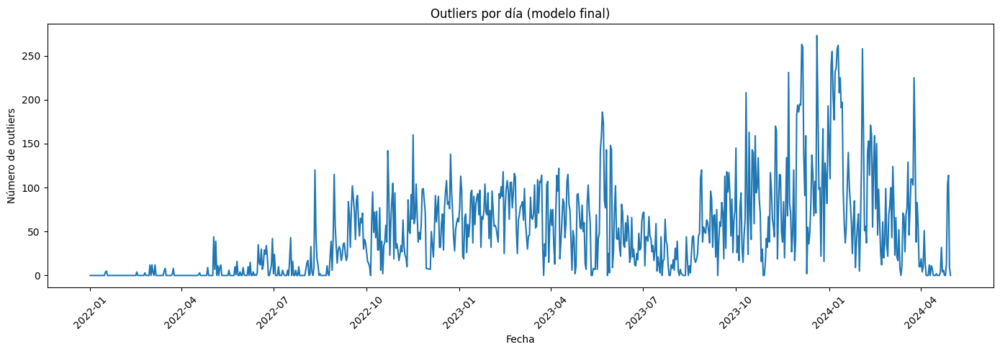

In [55]:
plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day_1['date'], outliers_by_day_1['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día (modelo final)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### When to retrain

In [56]:
window_days = 84
n_std = 3
MIN_OUTLIERS_DAY = 5   # guard: with mean=0 and std=0 the threshold is 0 and a single outlier would trigger

# Note: the window counts rows (days with data)
outliers_by_day_1['mean_window'] = outliers_by_day_1['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_1['std_window'] = outliers_by_day_1['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_1['threshold'] = outliers_by_day_1['mean_window'] + n_std*outliers_by_day_1['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_1['retrain'] = (
    (outliers_by_day_1['outliers'] > outliers_by_day_1['threshold']) &
    (outliers_by_day_1['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_1['date']) >= pd.Timestamp(cut_day_1))
)

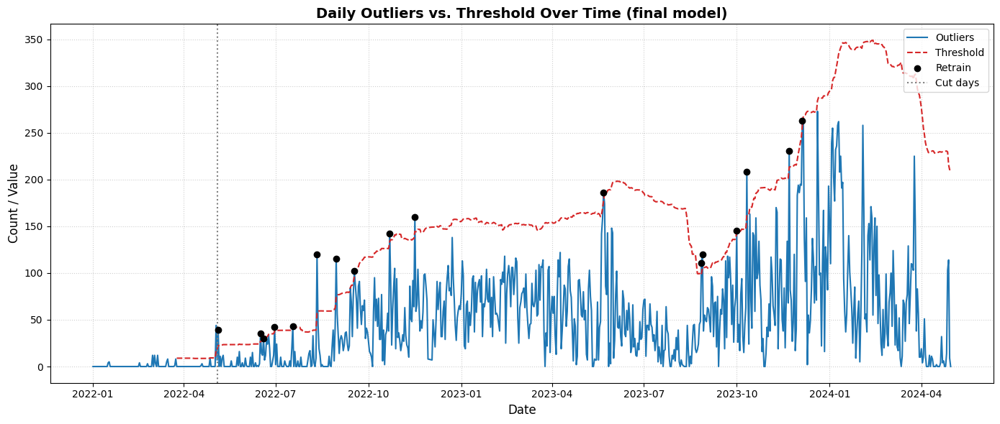

In [57]:
plt.figure(figsize=(14, 6))

dates_1 = pd.to_datetime(outliers_by_day_1['date'])
plt.plot(dates_1, outliers_by_day_1["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_1, outliers_by_day_1["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_1 = outliers_by_day_1[outliers_by_day_1['retrain']]
plt.scatter(pd.to_datetime(flagged_1['date']), flagged_1['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (final model)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [58]:
outliers_by_day_1[outliers_by_day_1['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
123,2022-05-05,39,287,13.588850,2.035714,6.827384,22.517865,True
165,2022-06-16,35,287,12.195122,3.071429,7.977054,27.002591,True
168,2022-06-19,30,287,10.452962,3.642857,8.597622,29.435723,True
179,2022-06-30,42,287,14.634146,5.857143,10.686263,37.915931,True
197,2022-07-18,43,287,14.982578,7.142857,11.528010,41.726886,True
221,2022-08-11,120,287,41.811847,8.333333,16.290535,57.204938,True
240,2022-08-30,115,287,40.069686,11.488095,20.849717,74.037246,True
258,2022-09-17,102,287,35.540070,17.404762,26.276619,96.234619,True
293,2022-10-22,142,287,49.477352,35.654762,32.679714,133.693904,True
318,2022-11-16,160,287,55.749129,47.940476,32.256260,144.709255,True


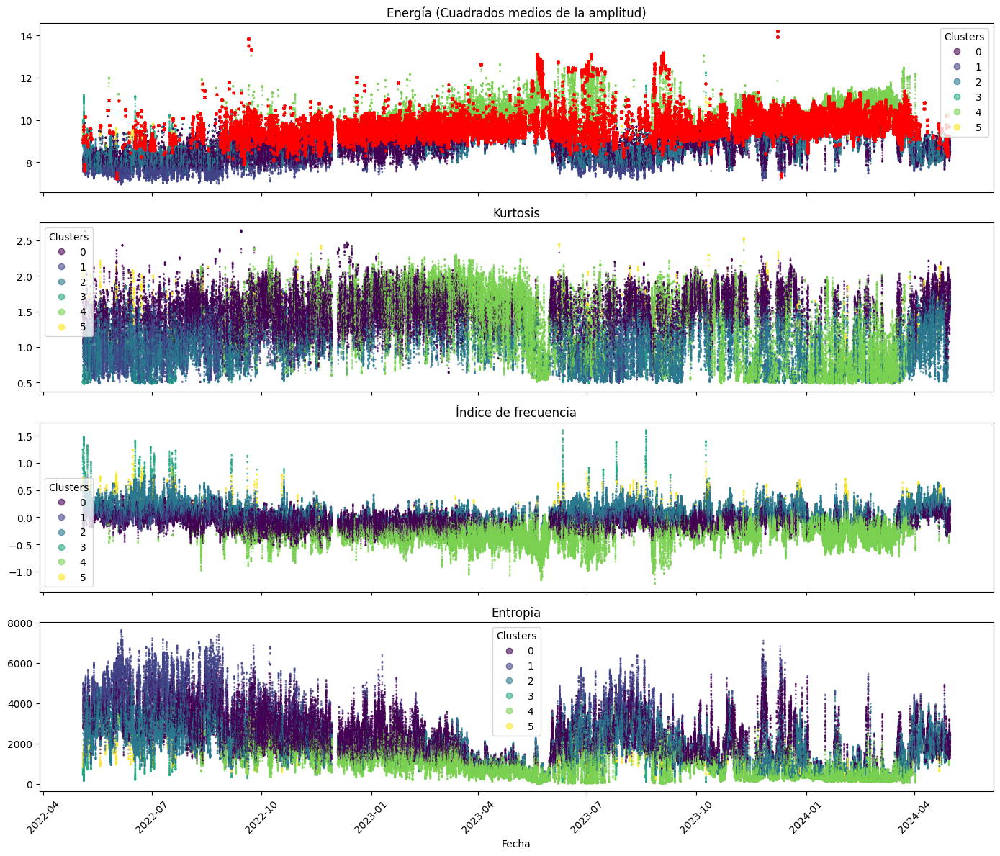

In [59]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(post_df['timestamp'], post_df['energy_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(post_df['timestamp'], post_df['kurtosis_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(post_df['timestamp'], post_df['frequency_index_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(post_df['timestamp'], post_df['entropy_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")

out = post_df[post_df['outliers']]
axes[0].scatter(out['timestamp'], out['energy_mobile_mean'], color='red', s=6, marker='x')

plt.xticks(rotation=45)
plt.tight_layout()

In [60]:
# First day that would trigger a new retraining
next_cut_1 = outliers_by_day_1.loc[outliers_by_day_1['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_1}")

Next retraining day: 2022-05-05


## Iteration 2 – retrain at `next_cut_1`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [61]:
# Same logic as iteration 1: the trigger day is included in the buffer
cut_day_2 = pd.Timestamp(next_cut_1) + pd.Timedelta(days=1)
ts_post = pd.to_datetime(post_df['timestamp'])

# Outliers of ALL the past according to the first final model (6 centroids) and its bound (upper_increment):
# (a) before the first cut (past_data_df, already scored)
mask_old_2 = past_data_df['outliers'].to_numpy()
# (b) between the first cut and the new cut day
mask_new_2 = ((ts_post < cut_day_2) & post_df['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_2 = pd.concat([past_data_df[mask_old_2][cols_buffer], post_df[mask_new_2][cols_buffer]]).copy()
Z_buffer_2 = np.vstack([Z_past[mask_old_2], Z_post[mask_new_2]])    # already scaled + PCA

print(f"Outliers en buffer 2: {len(buffer_2)}  (antes del primer corte: {mask_old_2.sum()} | entre cortes: {mask_new_2.sum()})")
print(buffer_2.groupby('date').size())

Outliers en buffer 2: 2429  (antes del primer corte: 2383 | entre cortes: 46)
date
2022-01-01    12
2022-01-03    12
2022-01-04    10
2022-01-05     9
2022-01-12     7
              ..
2022-04-27    16
2022-04-28     3
2022-04-30    11
2022-05-04     7
2022-05-05    39
Length: 74, dtype: int64


In [62]:
c_buffer = Z_buffer_2.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_2 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    2429.000000
mean        1.501362
std         1.146337
min         0.043028
25%         0.878640
50%         1.175034
75%         1.533027
max         6.619576
dtype: float64


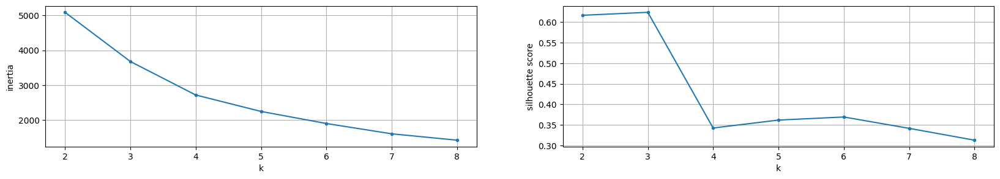

In [63]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_2 = []
silh_2 = []
k_s_2 = np.arange(2, min(9, len(Z_buffer_2)))
for k in k_s_2:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_2)
    inertia_2.append(km_model_aux.inertia_)
    silh_2.append(silhouette_score(Z_buffer_2, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_2, inertia_2, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_2, silh_2, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [64]:
K_NEW = 3   # adjust after looking at the plots above
km_model_buffer_2 = KMeans(n_clusters=K_NEW, random_state=9972, n_init=10).fit(Z_buffer_2)

clustering_data_buffer_2 = pd.DataFrame(Z_buffer_2, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_2['labels'] = km_model_buffer_2.labels_
clustering_data_buffer_2[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,2108
1,77
2,244


#### Promote the new groups

In [65]:
MIN_MIEMBROS_2 = 5   # the buffer is much smaller than in iteration 1 (134), so this needs to be lower; adjust

n_original_2 = len(centroides_expandidos)
promover_2 = []

for k in range(km_model_buffer_2.n_clusters):
    n = (km_model_buffer_2.labels_ == k).sum()
    if n >= MIN_MIEMBROS_2:
        promover_2.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_2 + len(promover_2) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_2 = {k: n_original_2 + i for i, k in enumerate(promover_2)}
print("Mapeo buffer → global:", mapping_2)

✓ Buffer 0 (2108 miembros) → será Cluster 6
✓ Buffer 1 (77 miembros) → será Cluster 7
✓ Buffer 2 (244 miembros) → será Cluster 8
Mapeo buffer → global: {0: 6, 1: 7, 2: 8}


In [66]:
nuevos_centroides_2 = km_model_buffer_2.cluster_centers_[promover_2]

centroides_expandidos_2 = np.vstack([centroides_expandidos, nuevos_centroides_2])
print(f"Centroides: {n_original_2} → {len(centroides_expandidos_2)}")

buffer_labels_globales_2 = np.array([mapping_2.get(lbl, -1) for lbl in km_model_buffer_2.labels_])
buffer_2['labels_nuevo'] = buffer_labels_globales_2
print(pd.Series(buffer_labels_globales_2).value_counts().sort_index())

Centroides: 6 → 9
6    2108
7      77
8     244
Name: count, dtype: int64


#### Changing the labels (between the first cut and the new cut)

In [67]:
past_data_df_2 = post_df[(ts_post < cut_day_2).to_numpy()].copy()

# Initialize with the labels of the first final model
past_data_df_2['labels_final'] = past_data_df_2['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_2 = buffer_2[buffer_2.index.isin(past_data_df_2.index)]
past_data_df_2.loc[buf_period_2.index, 'labels_final'] = buf_period_2['labels_nuevo']

# Tag the points that still are outliers
past_data_df_2['outliers_final'] = past_data_df_2['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_2['outliers'].sum()}")
print(f"Outliers después: {past_data_df_2['outliers_final'].sum()}\n")
print(past_data_df_2['labels_final'].value_counts().sort_index())

Outliers antes:   46
Outliers después: 0

labels_final
0    148
1    122
2    139
3     92
5     27
7     29
8     17
Name: count, dtype: int64


In [68]:
past_data_df_2

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid,outliers,date,labels_final,outliers_final
35301,2022-05-04 00:05:00,10.013976,0.517867,1.247520,439.188958,3,0.868403,False,2022-05-04,3,False
35302,2022-05-04 00:10:00,9.978827,0.515900,1.239584,457.877029,3,0.909793,False,2022-05-04,3,False
35303,2022-05-04 00:15:00,9.944814,0.516310,1.242556,479.593116,3,0.966674,False,2022-05-04,3,False
35304,2022-05-04 00:20:00,9.906881,0.516676,1.243378,503.104278,3,1.026448,False,2022-05-04,3,False
35305,2022-05-04 00:25:00,9.866769,0.512874,1.235413,525.695344,3,1.080877,False,2022-05-04,3,False
...,...,...,...,...,...,...,...,...,...,...,...
35870,2022-05-05 23:35:00,8.460826,0.661253,0.338152,1986.984375,2,1.496766,False,2022-05-05,2,False
35871,2022-05-05 23:40:00,8.406185,0.698574,0.333314,2064.292656,2,1.349123,False,2022-05-05,2,False
35872,2022-05-05 23:45:00,8.382084,0.749628,0.288631,2114.767230,2,1.122880,False,2022-05-05,2,False
35873,2022-05-05 23:50:00,8.357693,0.762766,0.247846,2175.843622,2,1.028988,False,2022-05-05,2,False


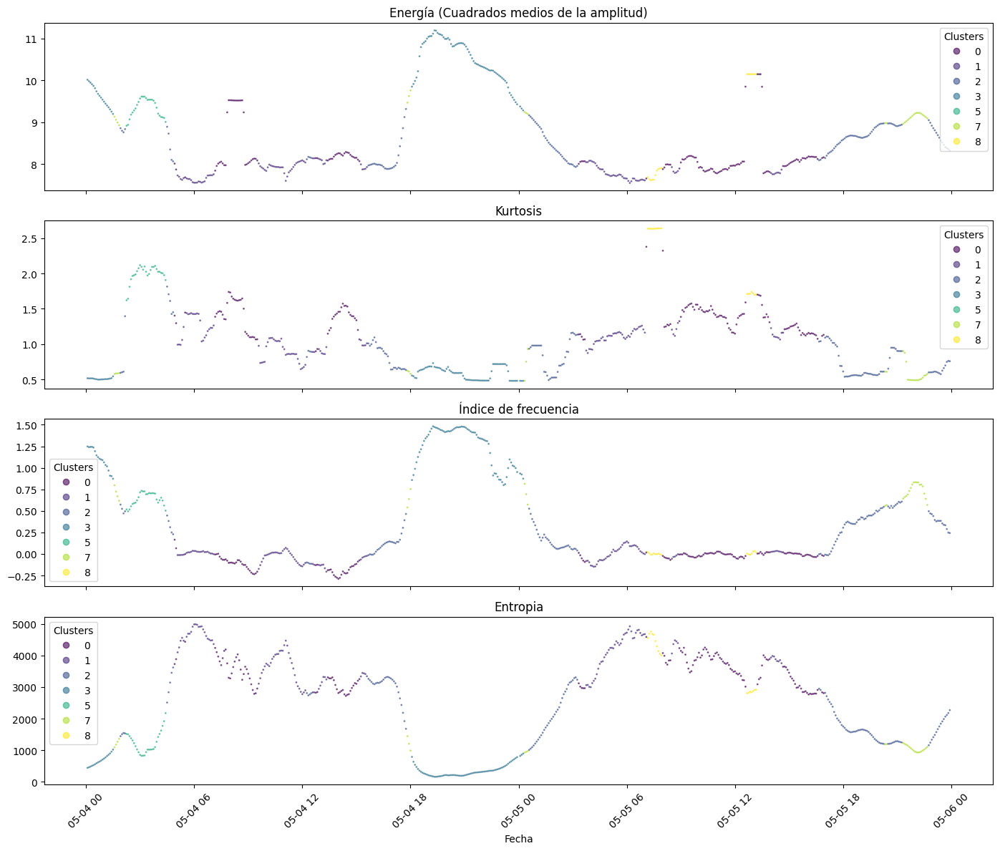

In [69]:
n_cl = len(centroides_expandidos_2)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_2['timestamp'], past_data_df_2[col], c=past_data_df_2['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [70]:
mask_post_2 = (ts_post >= cut_day_2).to_numpy()
post_df_2 = post_df[mask_post_2][['timestamp'] + feature_cols].copy()
Z_post_2 = Z_post[mask_post_2]

print(f"Observations after {cut_day_2.date()}: {len(post_df_2)}")

dist_post_2 = pairwise_distances(Z_post_2, centroides_expandidos_2)
post_df_2['labels'] = dist_post_2.argmin(axis=1)
post_df_2['distance_to_centroid'] = dist_post_2.min(axis=1)
print(post_df_2['labels'].value_counts().sort_index())

Observations after 2022-05-06: 205312
labels
0    31092
1    12995
2    33455
3      276
4    35461
5      587
6    34817
7     4217
8    52412
Name: count, dtype: int64


Outlier bound for iteration 2: computed with the distances of **all the data before the cut day** (training + first iteration), scored with the new model (8 centroids). Same rule as in iteration 1.

In [71]:
N_IQR = 1.5   # same multiplier as in iteration 1

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_2 = clustering_data_all[(ts_all < cut_day_2).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_2 = pca.transform(scaler.transform(past_all_2[feature_cols].to_numpy()))
dist_past_2 = pairwise_distances(Z_past_2, centroides_expandidos_2)
past_all_2['labels'] = dist_past_2.argmin(axis=1)
past_all_2['distance_to_centroid'] = dist_past_2.min(axis=1)

Q1 = past_all_2['distance_to_centroid'].quantile(0.25)
Q3 = past_all_2['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_2 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_2:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_2['outliers'] = past_all_2['distance_to_centroid'] > upper_increment_2
post_df_2['outliers'] = post_df_2['distance_to_centroid'] > upper_increment_2

print(f"Outliers in the past: {past_all_2['outliers'].sum()} ({100*past_all_2['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_2['outliers'].sum()} ({100*post_df_2['outliers'].mean():.2f}%)")

Q1: 0.887 | Q3: 1.518 | IQR: 0.631
Cota superior (Q3 + 1.5*IQR): 2.464
Outliers in the past: 346 (1.00%)
Outliers in the new data: 16427 (8.00%)


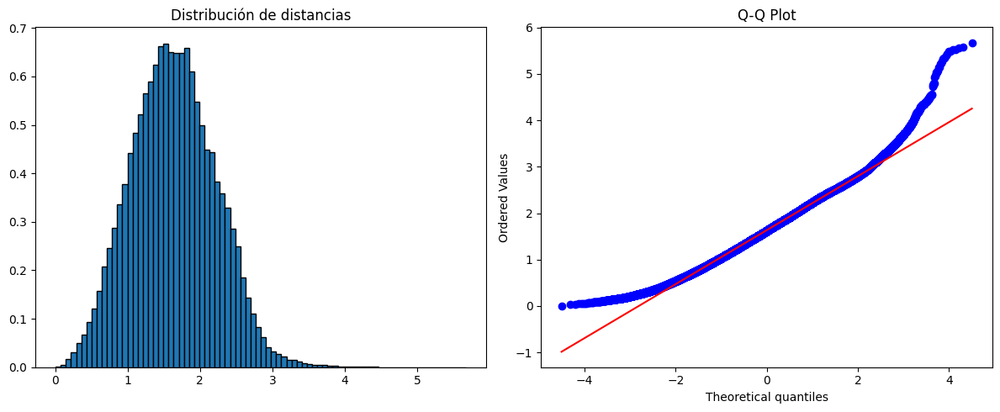

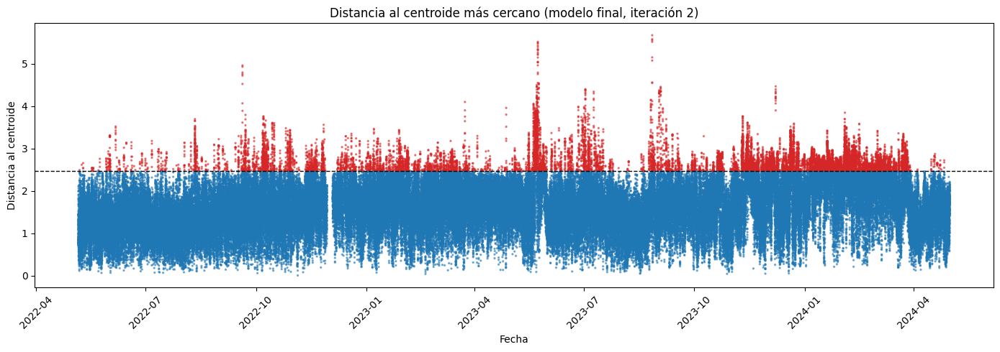

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_2['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_2['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_2['timestamp'], post_df_2['distance_to_centroid'],
            c=post_df_2['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_2, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 2)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [73]:
# The buffer of the next iteration needs the date of the past points
past_all_2['date'] = pd.to_datetime(past_all_2['timestamp']).dt.date
post_df_2['date'] = pd.to_datetime(post_df_2['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_2 = outliers_by_day_1[pd.to_datetime(outliers_by_day_1['date']) < cut_day_2][['date', 'outliers', 'total']]
else:
    gh = past_all_2.groupby('date')['outliers']
    hist_2 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_2.groupby('date')['outliers']
new_2 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_2 = pd.concat([hist_2, new_2]).reset_index(drop=True)
outliers_by_day_2['outliers_pct'] = 100 * outliers_by_day_2['outliers'] / outliers_by_day_2['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_2['mean_window'] = outliers_by_day_2['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_2['std_window'] = outliers_by_day_2['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_2['threshold'] = outliers_by_day_2['mean_window'] + n_std*outliers_by_day_2['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_2['retrain'] = (
    (outliers_by_day_2['outliers'] > outliers_by_day_2['threshold']) &
    (outliers_by_day_2['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_2['date']) >= pd.Timestamp(cut_day_2))
)

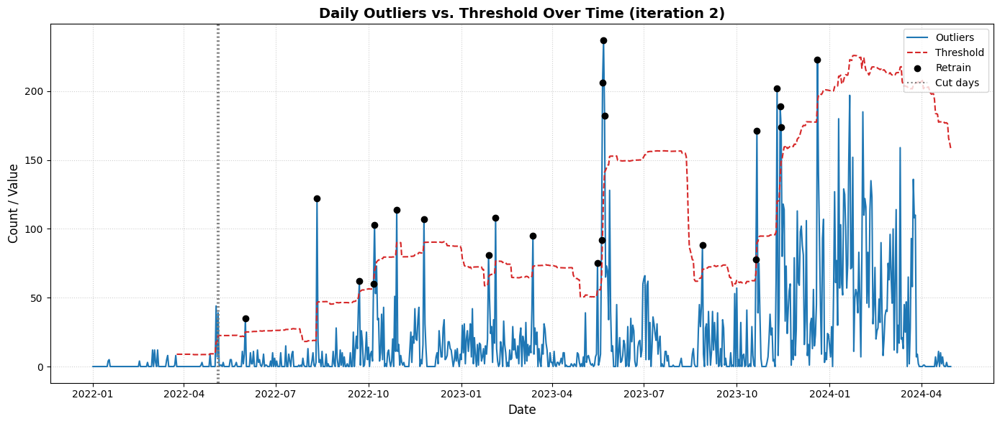

In [74]:
plt.figure(figsize=(14, 6))

dates_2 = pd.to_datetime(outliers_by_day_2['date'])
plt.plot(dates_2, outliers_by_day_2["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_2, outliers_by_day_2["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_2 = outliers_by_day_2[outliers_by_day_2['retrain']]
plt.scatter(pd.to_datetime(flagged_2['date']), flagged_2['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 2)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [75]:
outliers_by_day_2[outliers_by_day_2['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
150,2022-06-01,35,287,12.195122,2.392857,7.582507,25.140377,True
221,2022-08-11,122,287,42.508711,4.333333,14.043249,46.463081,True
263,2022-09-22,62,286,21.678322,6.416667,16.079028,54.653751,True
277,2022-10-06,60,287,20.905923,8.154762,17.242071,59.880975,True
278,2022-10-07,103,287,35.888502,9.333333,20.101150,69.636783,True
300,2022-10-29,114,287,39.721254,15.011905,24.993731,89.993099,True
327,2022-11-25,107,287,37.282230,17.142857,24.261201,89.926459,True
388,2023-01-28,81,287,28.222997,13.750000,16.994595,64.733786,True
395,2023-02-04,108,287,37.630662,16.809524,19.950225,76.660199,True
432,2023-03-13,95,287,33.101045,16.285714,18.876626,72.915593,True


In [76]:
next_cut_2 = outliers_by_day_2.loc[outliers_by_day_2['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_2}")

Next retraining day: 2022-06-01


## Iteration 3 – retrain at `next_cut_2`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [77]:
if pd.isna(next_cut_2):
    raise ValueError("next_cut_2 is empty: the previous iteration found no retraining day")

# Same logic as before: the trigger day is included in the buffer
cut_day_3 = pd.Timestamp(next_cut_2) + pd.Timedelta(days=1)
ts_post_2 = pd.to_datetime(post_df_2['timestamp'])

# Outliers of ALL the past according to the previous model and its bound (upper_increment_2):
# (a) before the previous cut (already scored in past_all_2)
mask_old_3 = past_all_2['outliers'].to_numpy()
# (b) between the previous cut and the new cut day
mask_new_3 = ((ts_post_2 < cut_day_3) & post_df_2['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_3 = pd.concat([past_all_2[mask_old_3][cols_buffer], post_df_2[mask_new_3][cols_buffer]]).copy()
Z_buffer_3 = np.vstack([Z_past_2[mask_old_3], Z_post_2[mask_new_3]])    # already scaled + PCA

print(f"Outliers en buffer 3: {len(buffer_3)}  (antes del corte anterior: {mask_old_3.sum()} | entre cortes: {mask_new_3.sum()})")
print(buffer_3.groupby('date').size())

Outliers en buffer 3: 422  (antes del corte anterior: 346 | entre cortes: 76)
date
2022-01-03     5
2022-01-05     4
2022-01-06    11
2022-01-11     1
2022-01-12     9
              ..
2022-05-23     3
2022-05-29    11
2022-05-30     2
2022-05-31     9
2022-06-01    35
Length: 63, dtype: int64


In [78]:
c_buffer = Z_buffer_3.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_3 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    422.000000
mean       3.291902
std        1.067171
min        1.656623
25%        2.529041
50%        3.389593
75%        3.752454
max       10.464842
dtype: float64


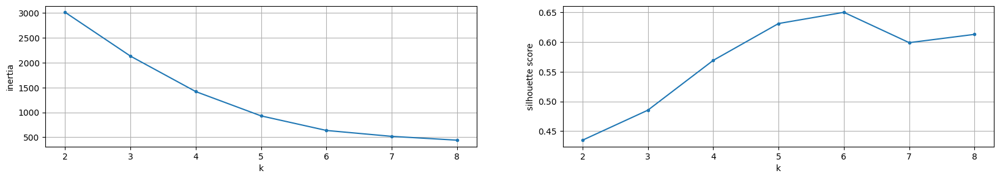

In [79]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_3 = []
silh_3 = []
k_s_3 = np.arange(2, min(9, len(Z_buffer_3)))
for k in k_s_3:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_3)
    inertia_3.append(km_model_aux.inertia_)
    silh_3.append(silhouette_score(Z_buffer_3, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_3, inertia_3, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_3, silh_3, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [80]:
K_NEW_3 = 6   # adjust after looking at the plots above
km_model_buffer_3 = KMeans(n_clusters=K_NEW_3, random_state=9972, n_init=10).fit(Z_buffer_3)

clustering_data_buffer_3 = pd.DataFrame(Z_buffer_3, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_3['labels'] = km_model_buffer_3.labels_
clustering_data_buffer_3[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,62
1,5
2,109
3,64
4,153
5,29


#### Promote the new groups

In [81]:
MIN_MIEMBROS_3 = 5   # adjust according to the size of the groups above

n_original_3 = len(centroides_expandidos_2)
promover_3 = []

for k in range(km_model_buffer_3.n_clusters):
    n = (km_model_buffer_3.labels_ == k).sum()
    if n >= MIN_MIEMBROS_3:
        promover_3.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_3 + len(promover_3) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_3 = {k: n_original_3 + i for i, k in enumerate(promover_3)}
print("Mapeo buffer → global:", mapping_3)

✓ Buffer 0 (62 miembros) → será Cluster 9
✓ Buffer 1 (5 miembros) → será Cluster 10
✓ Buffer 2 (109 miembros) → será Cluster 11
✓ Buffer 3 (64 miembros) → será Cluster 12
✓ Buffer 4 (153 miembros) → será Cluster 13
✓ Buffer 5 (29 miembros) → será Cluster 14
Mapeo buffer → global: {0: 9, 1: 10, 2: 11, 3: 12, 4: 13, 5: 14}


In [82]:
nuevos_centroides_3 = km_model_buffer_3.cluster_centers_[promover_3]

centroides_expandidos_3 = np.vstack([centroides_expandidos_2, nuevos_centroides_3])
print(f"Centroides: {n_original_3} → {len(centroides_expandidos_3)}")

buffer_labels_globales_3 = np.array([mapping_3.get(lbl, -1) for lbl in km_model_buffer_3.labels_])
buffer_3['labels_nuevo'] = buffer_labels_globales_3
print(pd.Series(buffer_labels_globales_3).value_counts().sort_index())

Centroides: 9 → 15
9      62
10      5
11    109
12     64
13    153
14     29
Name: count, dtype: int64


#### Changing the labels (between the previous cut and the new cut)

In [83]:
past_data_df_3 = post_df_2[(ts_post_2 < cut_day_3).to_numpy()].copy()

# Initialize with the labels of the previous final model
past_data_df_3['labels_final'] = past_data_df_3['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_3 = buffer_3[buffer_3.index.isin(past_data_df_3.index)]
past_data_df_3.loc[buf_period_3.index, 'labels_final'] = buf_period_3['labels_nuevo']

# Tag the points that still are outliers
past_data_df_3['outliers_final'] = past_data_df_3['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_3['outliers'].sum()}")
print(f"Outliers después: {past_data_df_3['outliers_final'].sum()}\n")
print(past_data_df_3['labels_final'].value_counts().sort_index())

Outliers antes:   76
Outliers después: 0

labels_final
0     1240
1     2000
2     3827
3       30
4       12
5      109
6       66
7      214
8      173
9       27
11       2
13      31
14      16
Name: count, dtype: int64


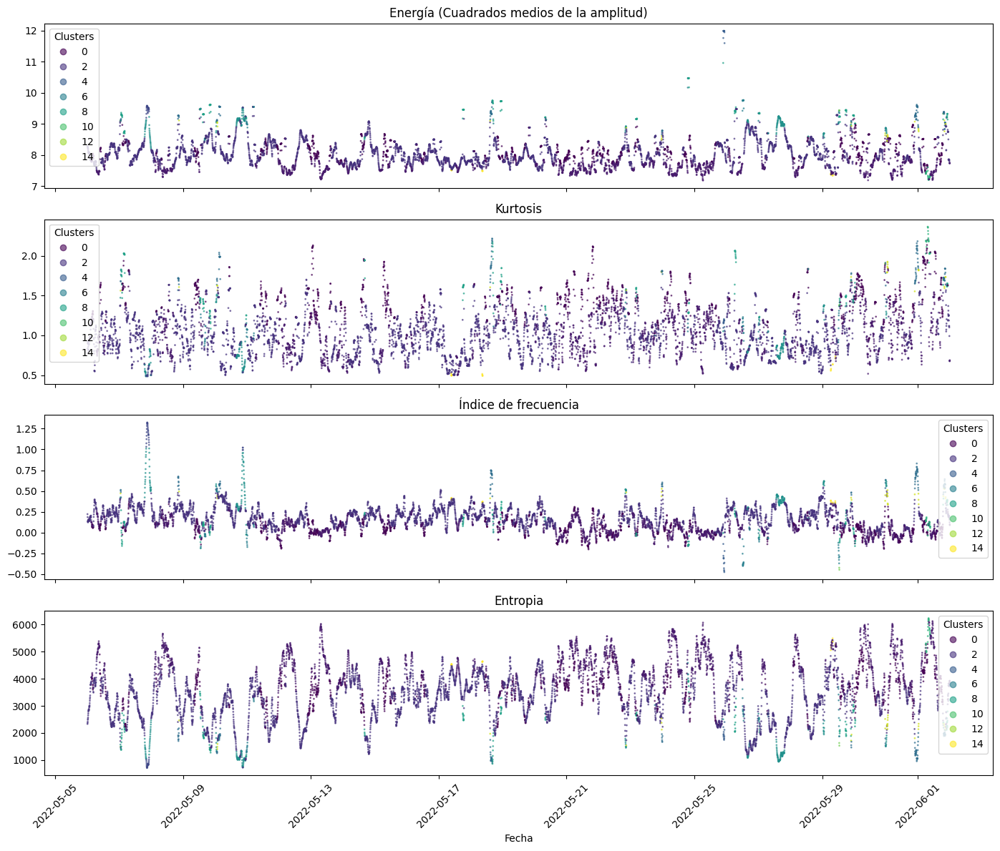

In [84]:
n_cl = len(centroides_expandidos_3)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_3['timestamp'], past_data_df_3[col], c=past_data_df_3['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [85]:
mask_post_3 = (ts_post_2 >= cut_day_3).to_numpy()
post_df_3 = post_df_2[mask_post_3][['timestamp'] + feature_cols].copy()
Z_post_3 = Z_post_2[mask_post_3]

print(f"Observations after {cut_day_3.date()}: {len(post_df_3)}")

dist_post_3 = pairwise_distances(Z_post_3, centroides_expandidos_3)
post_df_3['labels'] = dist_post_3.argmin(axis=1)
post_df_3['distance_to_centroid'] = dist_post_3.min(axis=1)
print(post_df_3['labels'].value_counts().sort_index())

Observations after 2022-06-02: 197565
labels
0     26510
1      9519
2     25060
3       220
4     34346
5       272
6     24542
7      2138
8     43524
9       280
10       26
11    12281
12    13821
13     3112
14     1914
Name: count, dtype: int64


Outlier bound for iteration 3: computed with the distances of **all the data before the cut day**, scored with the new model.

In [86]:
N_IQR = 1.5   # same multiplier as in the previous iterations

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_3 = clustering_data_all[(ts_all < cut_day_3).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_3 = pca.transform(scaler.transform(past_all_3[feature_cols].to_numpy()))
dist_past_3 = pairwise_distances(Z_past_3, centroides_expandidos_3)
past_all_3['labels'] = dist_past_3.argmin(axis=1)
past_all_3['distance_to_centroid'] = dist_past_3.min(axis=1)

Q1 = past_all_3['distance_to_centroid'].quantile(0.25)
Q3 = past_all_3['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_3 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_3:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_3['outliers'] = past_all_3['distance_to_centroid'] > upper_increment_3
post_df_3['outliers'] = post_df_3['distance_to_centroid'] > upper_increment_3

print(f"Outliers in the past: {past_all_3['outliers'].sum()} ({100*past_all_3['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_3['outliers'].sum()} ({100*post_df_3['outliers'].mean():.2f}%)")

Q1: 0.870 | Q3: 1.421 | IQR: 0.551
Cota superior (Q3 + 1.5*IQR): 2.247
Outliers in the past: 127 (0.30%)
Outliers in the new data: 21386 (10.82%)


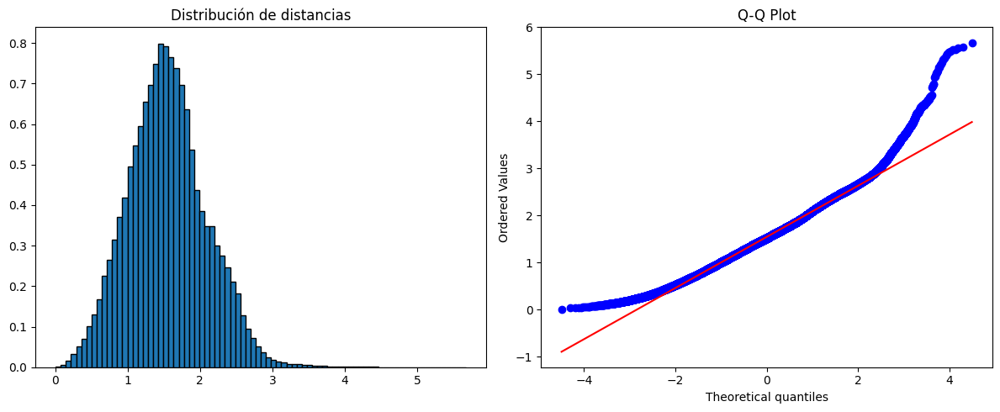

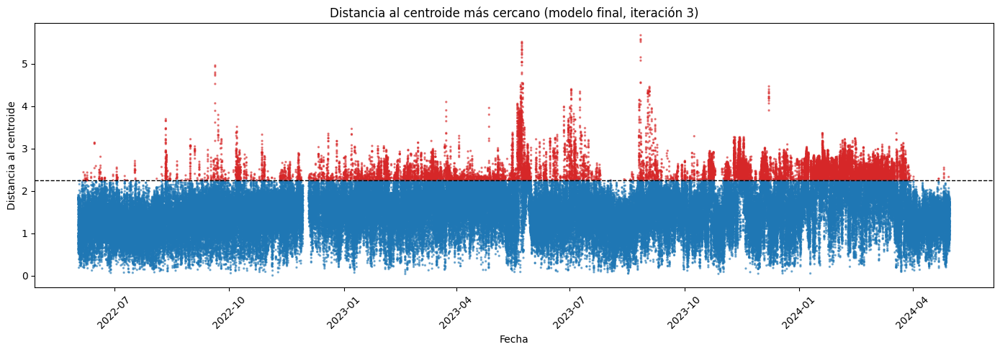

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_3['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_3['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_3['timestamp'], post_df_3['distance_to_centroid'],
            c=post_df_3['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_3, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 3)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [88]:
# The buffer of the next iteration needs the date of the past points
past_all_3['date'] = pd.to_datetime(past_all_3['timestamp']).dt.date
post_df_3['date'] = pd.to_datetime(post_df_3['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_3 = outliers_by_day_2[pd.to_datetime(outliers_by_day_2['date']) < cut_day_3][['date', 'outliers', 'total']]
else:
    gh = past_all_3.groupby('date')['outliers']
    hist_3 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_3.groupby('date')['outliers']
new_3 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_3 = pd.concat([hist_3, new_3]).reset_index(drop=True)
outliers_by_day_3['outliers_pct'] = 100 * outliers_by_day_3['outliers'] / outliers_by_day_3['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_3['mean_window'] = outliers_by_day_3['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_3['std_window'] = outliers_by_day_3['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_3['threshold'] = outliers_by_day_3['mean_window'] + n_std*outliers_by_day_3['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_3['retrain'] = (
    (outliers_by_day_3['outliers'] > outliers_by_day_3['threshold']) &
    (outliers_by_day_3['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_3['date']) >= pd.Timestamp(cut_day_3))
)

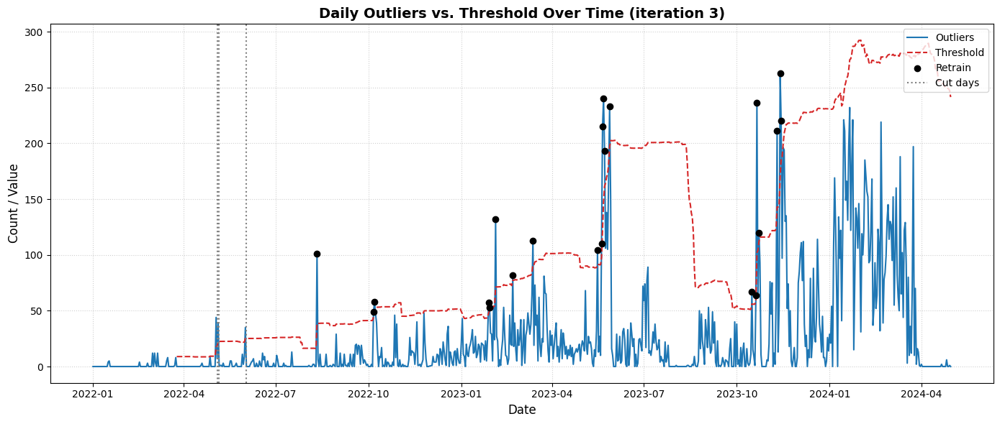

In [89]:
plt.figure(figsize=(14, 6))

dates_3 = pd.to_datetime(outliers_by_day_3['date'])
plt.plot(dates_3, outliers_by_day_3["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_3, outliers_by_day_3["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_3 = outliers_by_day_3[outliers_by_day_3['retrain']]
plt.scatter(pd.to_datetime(flagged_3['date']), flagged_3['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2, cut_day_3]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 3)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [90]:
outliers_by_day_3[outliers_by_day_3['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
221,2022-08-11,101,287,35.191638,3.119048,11.808109,38.543375,True
277,2022-10-06,49,287,17.073171,5.000000,13.187252,44.561756,True
278,2022-10-07,58,287,20.209059,5.690476,14.386218,48.849132,True
388,2023-01-28,57,287,19.860627,11.952381,11.879825,47.591855,True
389,2023-01-29,53,287,18.466899,12.583333,12.621657,50.448304,True
395,2023-02-04,132,287,45.993031,15.809524,18.434172,71.112040,True
412,2023-02-21,82,287,28.571429,17.630952,19.855975,77.198878,True
432,2023-03-13,113,287,39.372822,23.083333,22.786705,91.443449,True
496,2023-05-16,104,287,36.236934,25.797619,21.875761,91.424901,True
500,2023-05-20,110,287,38.327526,26.785714,23.633278,97.685549,True


In [91]:
next_cut_3 = outliers_by_day_3.loc[outliers_by_day_3['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_3}")

Next retraining day: 2022-08-11


## Iteration 4 – retrain at `next_cut_3`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [92]:
if pd.isna(next_cut_3):
    raise ValueError("next_cut_3 is empty: the previous iteration found no retraining day")

# Same logic as before: the trigger day is included in the buffer
cut_day_4 = pd.Timestamp(next_cut_3) + pd.Timedelta(days=1)
ts_post_3 = pd.to_datetime(post_df_3['timestamp'])

# Outliers of ALL the past according to the previous model and its bound (upper_increment_3):
# (a) before the previous cut (already scored in past_all_3)
mask_old_4 = past_all_3['outliers'].to_numpy()
# (b) between the previous cut and the new cut day
mask_new_4 = ((ts_post_3 < cut_day_4) & post_df_3['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_4 = pd.concat([past_all_3[mask_old_4][cols_buffer], post_df_3[mask_new_4][cols_buffer]]).copy()
Z_buffer_4 = np.vstack([Z_past_3[mask_old_4], Z_post_3[mask_new_4]])    # already scaled + PCA

print(f"Outliers en buffer 4: {len(buffer_4)}  (antes del corte anterior: {mask_old_4.sum()} | entre cortes: {mask_new_4.sum()})")
print(buffer_4.groupby('date').size())

Outliers en buffer 4: 328  (antes del corte anterior: 127 | entre cortes: 201)
date
2022-01-01      2
2022-01-11      5
2022-01-13      8
2022-01-15      1
2022-01-19      5
2022-01-20     12
2022-02-04      2
2022-02-13      3
2022-02-15      6
2022-02-16      8
2022-02-21      4
2022-02-24      2
2022-03-03      1
2022-03-04      4
2022-03-06      2
2022-03-07      3
2022-03-09      7
2022-03-16      2
2022-03-19      1
2022-03-20      1
2022-03-25      1
2022-03-26      5
2022-03-29      4
2022-03-30      1
2022-04-02      3
2022-04-06      4
2022-04-08      1
2022-04-11      8
2022-04-12      9
2022-04-19      2
2022-04-28      3
2022-05-03      4
2022-05-07      2
2022-05-25      1
2022-06-06      2
2022-06-07      4
2022-06-08      5
2022-06-09      7
2022-06-12      3
2022-06-15      5
2022-06-16      1
2022-06-18     12
2022-06-19      6
2022-06-20      9
2022-06-23      5
2022-06-29      3
2022-07-02     10
2022-07-03      6
2022-07-09      3
2022-07-11      1
2022-07-17     1

In [93]:
c_buffer = Z_buffer_4.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_4 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    328.000000
mean       4.159365
std        1.407563
min        2.048438
25%        3.119077
50%        3.721353
75%        4.619662
max        8.527338
dtype: float64


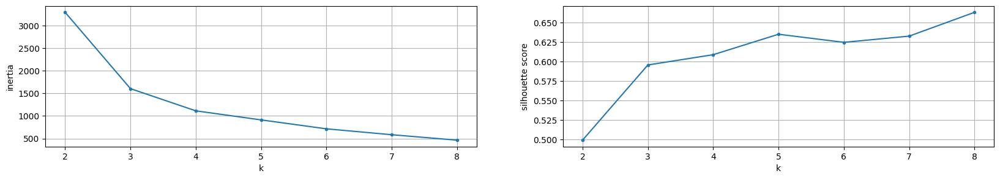

In [94]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_4 = []
silh_4 = []
k_s_4 = np.arange(2, min(9, len(Z_buffer_4)))
for k in k_s_4:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_4)
    inertia_4.append(km_model_aux.inertia_)
    silh_4.append(silhouette_score(Z_buffer_4, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_4, inertia_4, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_4, silh_4, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [96]:
K_NEW_4 = 8   # adjust after looking at the plots above
km_model_buffer_4 = KMeans(n_clusters=K_NEW_4, random_state=9972, n_init=10).fit(Z_buffer_4)

clustering_data_buffer_4 = pd.DataFrame(Z_buffer_4, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_4['labels'] = km_model_buffer_4.labels_
clustering_data_buffer_4[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,21
1,29
2,22
3,71
4,51
5,112
6,9
7,13


#### Promote the new groups

In [97]:
MIN_MIEMBROS_4 = 5   # adjust according to the size of the groups above

n_original_4 = len(centroides_expandidos_3)
promover_4 = []

for k in range(km_model_buffer_4.n_clusters):
    n = (km_model_buffer_4.labels_ == k).sum()
    if n >= MIN_MIEMBROS_4:
        promover_4.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_4 + len(promover_4) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_4 = {k: n_original_4 + i for i, k in enumerate(promover_4)}
print("Mapeo buffer → global:", mapping_4)

✓ Buffer 0 (21 miembros) → será Cluster 15
✓ Buffer 1 (29 miembros) → será Cluster 16
✓ Buffer 2 (22 miembros) → será Cluster 17
✓ Buffer 3 (71 miembros) → será Cluster 18
✓ Buffer 4 (51 miembros) → será Cluster 19
✓ Buffer 5 (112 miembros) → será Cluster 20
✓ Buffer 6 (9 miembros) → será Cluster 21
✓ Buffer 7 (13 miembros) → será Cluster 22
Mapeo buffer → global: {0: 15, 1: 16, 2: 17, 3: 18, 4: 19, 5: 20, 6: 21, 7: 22}


In [98]:
nuevos_centroides_4 = km_model_buffer_4.cluster_centers_[promover_4]

centroides_expandidos_4 = np.vstack([centroides_expandidos_3, nuevos_centroides_4])
print(f"Centroides: {n_original_4} → {len(centroides_expandidos_4)}")

buffer_labels_globales_4 = np.array([mapping_4.get(lbl, -1) for lbl in km_model_buffer_4.labels_])
buffer_4['labels_nuevo'] = buffer_labels_globales_4
print(pd.Series(buffer_labels_globales_4).value_counts().sort_index())

Centroides: 15 → 23
15     21
16     29
17     22
18     71
19     51
20    112
21      9
22     13
Name: count, dtype: int64


#### Changing the labels (between the previous cut and the new cut)

In [99]:
past_data_df_4 = post_df_3[(ts_post_3 < cut_day_4).to_numpy()].copy()

# Initialize with the labels of the previous final model
past_data_df_4['labels_final'] = past_data_df_4['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_4 = buffer_4[buffer_4.index.isin(past_data_df_4.index)]
past_data_df_4.loc[buf_period_4.index, 'labels_final'] = buf_period_4['labels_nuevo']

# Tag the points that still are outliers
past_data_df_4['outliers_final'] = past_data_df_4['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_4['outliers'].sum()}")
print(f"Outliers después: {past_data_df_4['outliers_final'].sum()}\n")
print(past_data_df_4['labels_final'].value_counts().sort_index())

Outliers antes:   201
Outliers después: 0

labels_final
0     4171
1     4613
2     7155
3      116
4       18
5       93
6      271
7      894
8      679
9      115
10       1
11     283
12     263
13     473
14    1030
16      11
17      19
18      33
19      34
20      95
22       9
Name: count, dtype: int64


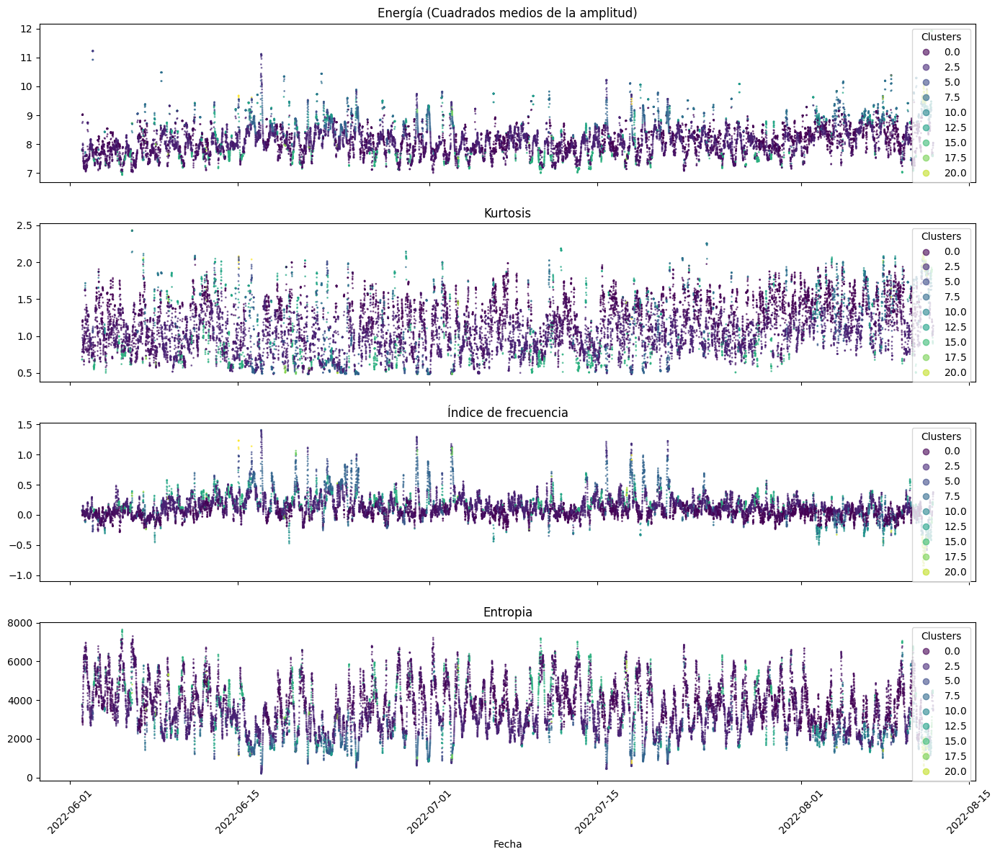

In [100]:
n_cl = len(centroides_expandidos_4)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_4['timestamp'], past_data_df_4[col], c=past_data_df_4['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [101]:
mask_post_4 = (ts_post_3 >= cut_day_4).to_numpy()
post_df_4 = post_df_3[mask_post_4][['timestamp'] + feature_cols].copy()
Z_post_4 = Z_post_3[mask_post_4]

print(f"Observations after {cut_day_4.date()}: {len(post_df_4)}")

dist_post_4 = pairwise_distances(Z_post_4, centroides_expandidos_4)
post_df_4['labels'] = dist_post_4.argmin(axis=1)
post_df_4['distance_to_centroid'] = dist_post_4.min(axis=1)
print(post_df_4['labels'].value_counts().sort_index())

Observations after 2022-08-12: 177189
labels
0     21273
1      3344
2     16074
3        78
4     26633
5       163
6     22826
7      1166
8     34014
9       106
10       25
11     8685
12    13268
13     2599
14      642
15       42
16     7179
17       73
18     4773
19      980
20    12909
21      328
22        9
Name: count, dtype: int64


Outlier bound for iteration 4: computed with the distances of **all the data before the cut day**, scored with the new model.

In [102]:
N_IQR = 1.5   # same multiplier as in the previous iterations

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_4 = clustering_data_all[(ts_all < cut_day_4).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_4 = pca.transform(scaler.transform(past_all_4[feature_cols].to_numpy()))
dist_past_4 = pairwise_distances(Z_past_4, centroides_expandidos_4)
past_all_4['labels'] = dist_past_4.argmin(axis=1)
past_all_4['distance_to_centroid'] = dist_past_4.min(axis=1)

Q1 = past_all_4['distance_to_centroid'].quantile(0.25)
Q3 = past_all_4['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_4 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_4:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_4['outliers'] = past_all_4['distance_to_centroid'] > upper_increment_4
post_df_4['outliers'] = post_df_4['distance_to_centroid'] > upper_increment_4

print(f"Outliers in the past: {past_all_4['outliers'].sum()} ({100*past_all_4['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_4['outliers'].sum()} ({100*post_df_4['outliers'].mean():.2f}%)")

Q1: 0.868 | Q3: 1.356 | IQR: 0.489
Cota superior (Q3 + 1.5*IQR): 2.089
Outliers in the past: 75 (0.12%)
Outliers in the new data: 22022 (12.43%)


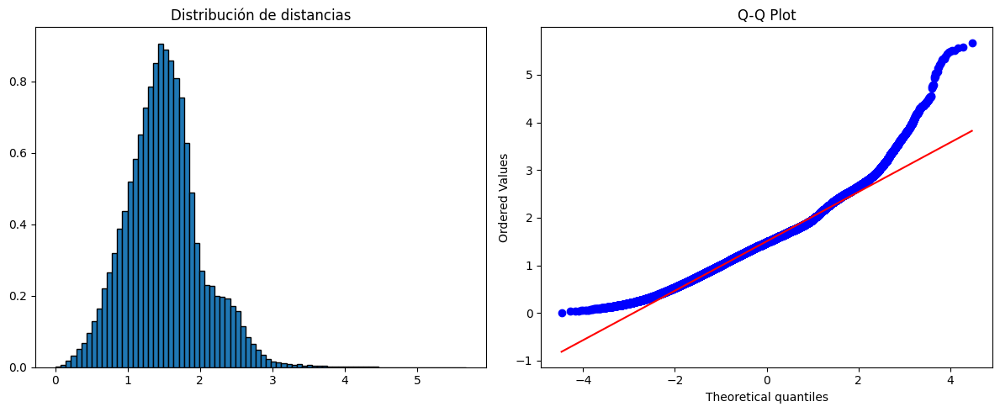

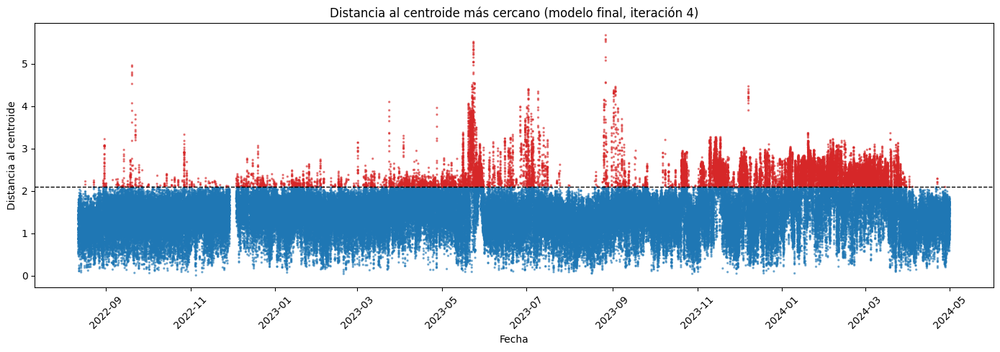

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_4['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_4['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_4['timestamp'], post_df_4['distance_to_centroid'],
            c=post_df_4['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_4, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 4)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [104]:
# The buffer of the next iteration needs the date of the past points
past_all_4['date'] = pd.to_datetime(past_all_4['timestamp']).dt.date
post_df_4['date'] = pd.to_datetime(post_df_4['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_4 = outliers_by_day_3[pd.to_datetime(outliers_by_day_3['date']) < cut_day_4][['date', 'outliers', 'total']]
else:
    gh = past_all_4.groupby('date')['outliers']
    hist_4 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_4.groupby('date')['outliers']
new_4 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_4 = pd.concat([hist_4, new_4]).reset_index(drop=True)
outliers_by_day_4['outliers_pct'] = 100 * outliers_by_day_4['outliers'] / outliers_by_day_4['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_4['mean_window'] = outliers_by_day_4['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_4['std_window'] = outliers_by_day_4['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_4['threshold'] = outliers_by_day_4['mean_window'] + n_std*outliers_by_day_4['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_4['retrain'] = (
    (outliers_by_day_4['outliers'] > outliers_by_day_4['threshold']) &
    (outliers_by_day_4['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_4['date']) >= pd.Timestamp(cut_day_4))
)

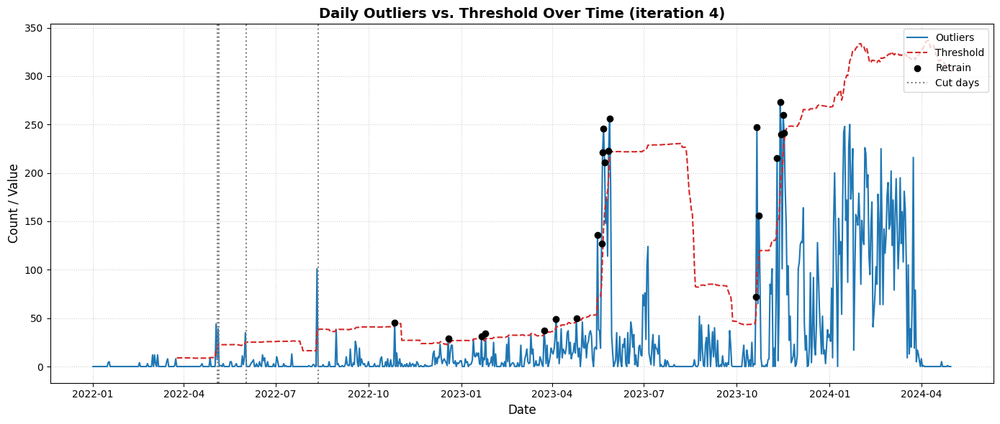

In [105]:
plt.figure(figsize=(14, 6))

dates_4 = pd.to_datetime(outliers_by_day_4['date'])
plt.plot(dates_4, outliers_by_day_4["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_4, outliers_by_day_4["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_4 = outliers_by_day_4[outliers_by_day_4['retrain']]
plt.scatter(pd.to_datetime(flagged_4['date']), flagged_4['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2, cut_day_3, cut_day_4]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 4)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [106]:
outliers_by_day_4[outliers_by_day_4['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
298,2022-10-27,45,287,15.679443,4.523810,13.165743,44.021037,True
348,2022-12-19,29,287,10.104530,3.821429,6.881371,24.465542,True
381,2023-01-21,31,287,10.801394,6.023810,8.275346,30.849848,True
385,2023-01-25,34,287,11.846690,5.916667,7.649251,28.864420,True
443,2023-03-24,37,287,12.891986,6.809524,9.106434,34.128825,True
455,2023-04-05,49,287,17.073171,8.869048,10.783499,41.219544,True
475,2023-04-25,50,287,17.421603,11.154762,12.299960,48.054642,True
496,2023-05-16,136,287,47.386760,16.250000,18.384694,71.404083,True
500,2023-05-20,127,287,44.250871,18.845238,21.869544,84.453871,True
501,2023-05-21,221,287,77.003484,21.428571,31.003803,114.439980,True


In [107]:
next_cut_4 = outliers_by_day_4.loc[outliers_by_day_4['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_4}")

Next retraining day: 2022-10-27


## Iteration 5 – retrain at `next_cut_4`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [108]:
if pd.isna(next_cut_4):
    raise ValueError("next_cut_4 is empty: the previous iteration found no retraining day")

# Same logic as before: the trigger day is included in the buffer
cut_day_5 = pd.Timestamp(next_cut_4) + pd.Timedelta(days=1)
ts_post_4 = pd.to_datetime(post_df_4['timestamp'])

# Outliers of ALL the past according to the previous model and its bound (upper_increment_4):
# (a) before the previous cut (already scored in past_all_4)
mask_old_5 = past_all_4['outliers'].to_numpy()
# (b) between the previous cut and the new cut day
mask_new_5 = ((ts_post_4 < cut_day_5) & post_df_4['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_5 = pd.concat([past_all_4[mask_old_5][cols_buffer], post_df_4[mask_new_5][cols_buffer]]).copy()
Z_buffer_5 = np.vstack([Z_past_4[mask_old_5], Z_post_4[mask_new_5]])    # already scaled + PCA

print(f"Outliers en buffer 5: {len(buffer_5)}  (antes del corte anterior: {mask_old_5.sum()} | entre cortes: {mask_new_5.sum()})")
print(buffer_5.groupby('date').size())

Outliers en buffer 5: 350  (antes del corte anterior: 75 | entre cortes: 275)
date
2022-01-11     4
2022-03-03     6
2022-03-06     2
2022-03-09     7
2022-03-10     1
2022-03-16     2
2022-05-07     2
2022-05-10     1
2022-06-02     2
2022-06-06     4
2022-06-14     5
2022-06-15     1
2022-06-16     5
2022-06-23     8
2022-07-11     1
2022-07-14    13
2022-07-17     1
2022-08-06     1
2022-08-08     2
2022-08-11     7
2022-08-17     2
2022-08-23     5
2022-08-30    38
2022-08-31     2
2022-09-01     3
2022-09-05     1
2022-09-08     2
2022-09-09    10
2022-09-10     2
2022-09-11     1
2022-09-12     1
2022-09-13    18
2022-09-14     1
2022-09-16     4
2022-09-17     2
2022-09-18    26
2022-09-19    21
2022-09-20     4
2022-09-22    19
2022-09-23     1
2022-09-24     8
2022-09-25     4
2022-09-26     2
2022-09-27     3
2022-09-30     1
2022-10-01     5
2022-10-07     3
2022-10-10     1
2022-10-13     8
2022-10-14    10
2022-10-18     5
2022-10-20     8
2022-10-23     7
2022-10-26     2

In [109]:
c_buffer = Z_buffer_5.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_5 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    350.000000
mean       3.317718
std        2.070208
min        0.164298
25%        1.769510
50%        3.042002
75%        4.889071
max        7.602104
dtype: float64


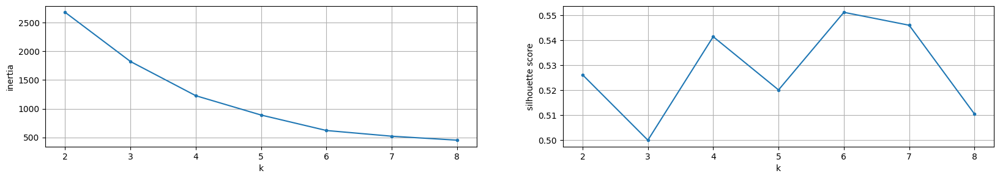

In [110]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_5 = []
silh_5 = []
k_s_5 = np.arange(2, min(9, len(Z_buffer_5)))
for k in k_s_5:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_5)
    inertia_5.append(km_model_aux.inertia_)
    silh_5.append(silhouette_score(Z_buffer_5, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_5, inertia_5, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_5, silh_5, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [111]:
K_NEW_5 = 6   # adjust after looking at the plots above
km_model_buffer_5 = KMeans(n_clusters=K_NEW_5, random_state=9972, n_init=10).fit(Z_buffer_5)

clustering_data_buffer_5 = pd.DataFrame(Z_buffer_5, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_5['labels'] = km_model_buffer_5.labels_
clustering_data_buffer_5[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,90
1,36
2,113
3,34
4,47
5,30


#### Promote the new groups

In [112]:
MIN_MIEMBROS_5 = 5   # adjust according to the size of the groups above

n_original_5 = len(centroides_expandidos_4)
promover_5 = []

for k in range(km_model_buffer_5.n_clusters):
    n = (km_model_buffer_5.labels_ == k).sum()
    if n >= MIN_MIEMBROS_5:
        promover_5.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_5 + len(promover_5) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_5 = {k: n_original_5 + i for i, k in enumerate(promover_5)}
print("Mapeo buffer → global:", mapping_5)

✓ Buffer 0 (90 miembros) → será Cluster 23
✓ Buffer 1 (36 miembros) → será Cluster 24
✓ Buffer 2 (113 miembros) → será Cluster 25
✓ Buffer 3 (34 miembros) → será Cluster 26
✓ Buffer 4 (47 miembros) → será Cluster 27
✓ Buffer 5 (30 miembros) → será Cluster 28
Mapeo buffer → global: {0: 23, 1: 24, 2: 25, 3: 26, 4: 27, 5: 28}


In [113]:
nuevos_centroides_5 = km_model_buffer_5.cluster_centers_[promover_5]

centroides_expandidos_5 = np.vstack([centroides_expandidos_4, nuevos_centroides_5])
print(f"Centroides: {n_original_5} → {len(centroides_expandidos_5)}")

buffer_labels_globales_5 = np.array([mapping_5.get(lbl, -1) for lbl in km_model_buffer_5.labels_])
buffer_5['labels_nuevo'] = buffer_labels_globales_5
print(pd.Series(buffer_labels_globales_5).value_counts().sort_index())

Centroides: 23 → 29
23     90
24     36
25    113
26     34
27     47
28     30
Name: count, dtype: int64


#### Changing the labels (between the previous cut and the new cut)

In [114]:
past_data_df_5 = post_df_4[(ts_post_4 < cut_day_5).to_numpy()].copy()

# Initialize with the labels of the previous final model
past_data_df_5['labels_final'] = past_data_df_5['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_5 = buffer_5[buffer_5.index.isin(past_data_df_5.index)]
past_data_df_5.loc[buf_period_5.index, 'labels_final'] = buf_period_5['labels_nuevo']

# Tag the points that still are outliers
past_data_df_5['outliers_final'] = past_data_df_5['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_5['outliers'].sum()}")
print(f"Outliers después: {past_data_df_5['outliers_final'].sum()}\n")
print(past_data_df_5['labels_final'].value_counts().sort_index())

Outliers antes:   275
Outliers después: 0

labels_final
0     5445
1     1608
2     2313
3       14
4      188
5       19
6     2363
7      150
8     2770
9       24
11    2551
12     747
13     195
14     283
15      31
16     220
17      11
18    1173
19     498
20    1093
21     126
22       1
23      81
24       2
25     113
26      29
27      35
28      15
Name: count, dtype: int64


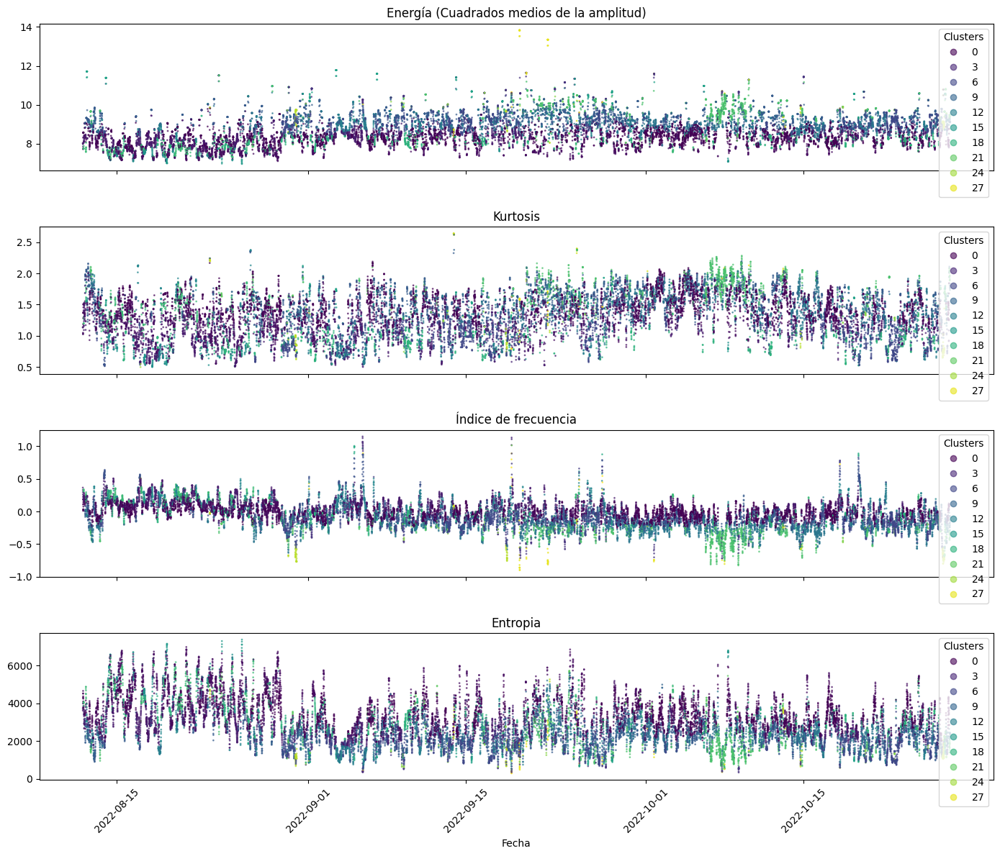

In [115]:
n_cl = len(centroides_expandidos_5)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_5['timestamp'], past_data_df_5[col], c=past_data_df_5['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [116]:
mask_post_5 = (ts_post_4 >= cut_day_5).to_numpy()
post_df_5 = post_df_4[mask_post_5][['timestamp'] + feature_cols].copy()
Z_post_5 = Z_post_4[mask_post_5]

print(f"Observations after {cut_day_5.date()}: {len(post_df_5)}")

dist_post_5 = pairwise_distances(Z_post_5, centroides_expandidos_5)
post_df_5['labels'] = dist_post_5.argmin(axis=1)
post_df_5['distance_to_centroid'] = dist_post_5.min(axis=1)
print(post_df_5['labels'].value_counts().sort_index())

Observations after 2022-10-28: 155091
labels
0     15527
1      1736
2     13522
3        63
4     17442
5        77
6     10685
7       657
8     24394
9        75
10       25
11     4192
12    11718
13     2254
14      359
15       11
16     3677
17       62
18     3598
19      476
20     7941
21      192
22        8
23    31442
24      320
25     1222
26     1037
27     1551
28      828
Name: count, dtype: int64


Outlier bound for iteration 5: computed with the distances of **all the data before the cut day**, scored with the new model.

In [117]:
N_IQR = 1.5   # same multiplier as in the previous iterations

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_5 = clustering_data_all[(ts_all < cut_day_5).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_5 = pca.transform(scaler.transform(past_all_5[feature_cols].to_numpy()))
dist_past_5 = pairwise_distances(Z_past_5, centroides_expandidos_5)
past_all_5['labels'] = dist_past_5.argmin(axis=1)
past_all_5['distance_to_centroid'] = dist_past_5.min(axis=1)

Q1 = past_all_5['distance_to_centroid'].quantile(0.25)
Q3 = past_all_5['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_5 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_5:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_5['outliers'] = past_all_5['distance_to_centroid'] > upper_increment_5
post_df_5['outliers'] = post_df_5['distance_to_centroid'] > upper_increment_5

print(f"Outliers in the past: {past_all_5['outliers'].sum()} ({100*past_all_5['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_5['outliers'].sum()} ({100*post_df_5['outliers'].mean():.2f}%)")

Q1: 0.893 | Q3: 1.382 | IQR: 0.489
Cota superior (Q3 + 1.5*IQR): 2.116
Outliers in the past: 37 (0.04%)
Outliers in the new data: 15499 (9.99%)


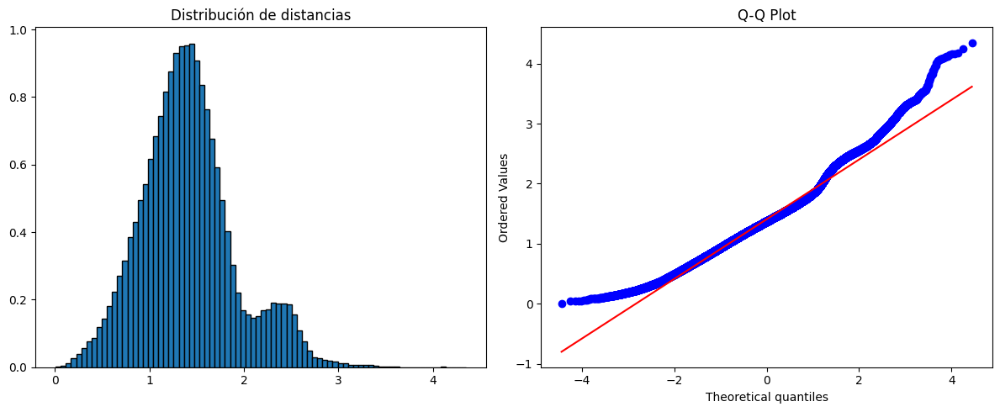

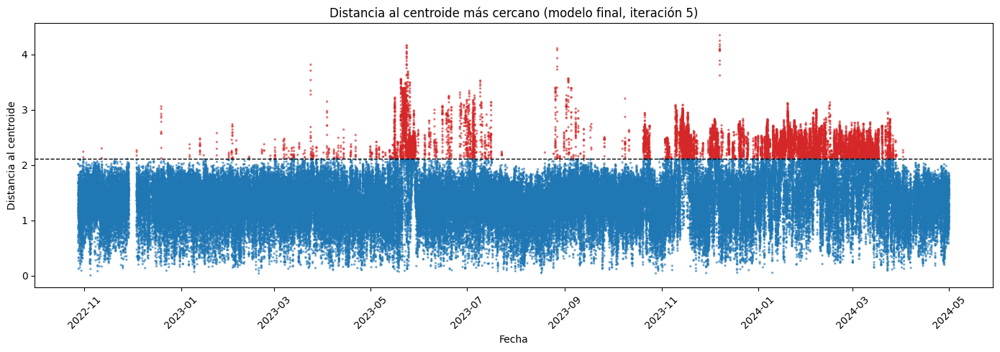

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_5['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_5['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_5['timestamp'], post_df_5['distance_to_centroid'],
            c=post_df_5['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_5, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 5)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [119]:
# The buffer of the next iteration needs the date of the past points
past_all_5['date'] = pd.to_datetime(past_all_5['timestamp']).dt.date
post_df_5['date'] = pd.to_datetime(post_df_5['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_5 = outliers_by_day_4[pd.to_datetime(outliers_by_day_4['date']) < cut_day_5][['date', 'outliers', 'total']]
else:
    gh = past_all_5.groupby('date')['outliers']
    hist_5 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_5.groupby('date')['outliers']
new_5 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_5 = pd.concat([hist_5, new_5]).reset_index(drop=True)
outliers_by_day_5['outliers_pct'] = 100 * outliers_by_day_5['outliers'] / outliers_by_day_5['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_5['mean_window'] = outliers_by_day_5['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_5['std_window'] = outliers_by_day_5['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_5['threshold'] = outliers_by_day_5['mean_window'] + n_std*outliers_by_day_5['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_5['retrain'] = (
    (outliers_by_day_5['outliers'] > outliers_by_day_5['threshold']) &
    (outliers_by_day_5['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_5['date']) >= pd.Timestamp(cut_day_5))
)

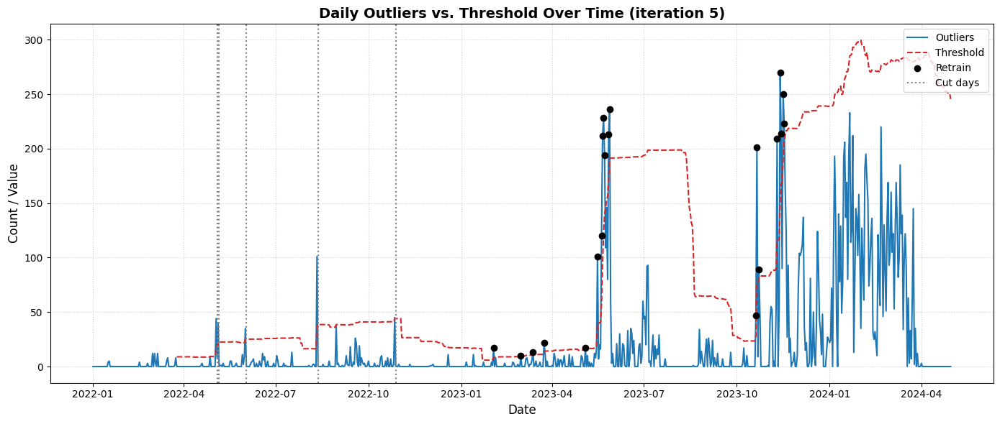

In [120]:
plt.figure(figsize=(14, 6))

dates_5 = pd.to_datetime(outliers_by_day_5['date'])
plt.plot(dates_5, outliers_by_day_5["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_5, outliers_by_day_5["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_5 = outliers_by_day_5[outliers_by_day_5['retrain']]
plt.scatter(pd.to_datetime(flagged_5['date']), flagged_5['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2, cut_day_3, cut_day_4, cut_day_5]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 5)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [121]:
outliers_by_day_5[outliers_by_day_5['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
393,2023-02-02,17,287,5.923345,0.690476,2.574089,8.412742,True
420,2023-03-01,10,287,3.484321,0.988095,2.906138,9.706510,True
432,2023-03-13,13,287,4.529617,1.345238,3.190702,10.917344,True
443,2023-03-24,22,287,7.665505,1.738095,3.912042,13.474222,True
484,2023-05-04,17,287,5.923345,2.654762,4.529672,16.243778,True
496,2023-05-16,101,287,35.191638,4.404762,11.735149,39.610208,True
500,2023-05-20,120,287,41.811847,6.309524,17.289858,58.179097,True
501,2023-05-21,212,287,73.867596,8.809524,28.321934,93.775326,True
502,2023-05-22,228,287,79.442509,11.523810,37.048479,122.669246,True
503,2023-05-23,194,287,67.595819,13.833333,42.032928,139.932118,True


In [122]:
next_cut_5 = outliers_by_day_5.loc[outliers_by_day_5['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_5}")

Next retraining day: 2023-02-02


## Iteration 6 – retrain at `next_cut_5`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [124]:
if pd.isna(next_cut_5):
    raise ValueError("next_cut_5 is empty: the previous iteration found no retraining day")

# Same logic as before: the trigger day is included in the buffer
cut_day_6 = pd.Timestamp(next_cut_5) + pd.Timedelta(days=1)
ts_post_5 = pd.to_datetime(post_df_5['timestamp'])

# Outliers of ALL the past according to the previous model and its bound (upper_increment_5):
# (a) before the previous cut (already scored in past_all_5)
mask_old_6 = past_all_5['outliers'].to_numpy()
# (b) between the previous cut and the new cut day
mask_new_6 = ((ts_post_5 < cut_day_6) & post_df_5['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_6 = pd.concat([past_all_5[mask_old_6][cols_buffer], post_df_5[mask_new_6][cols_buffer]]).copy()
Z_buffer_6 = np.vstack([Z_past_5[mask_old_6], Z_post_5[mask_new_6]])    # already scaled + PCA

print(f"Outliers en buffer 6: {len(buffer_6)}  (antes del corte anterior: {mask_old_6.sum()} | entre cortes: {mask_new_6.sum()})")
print(buffer_6.groupby('date').size())

Outliers en buffer 6: 97  (antes del corte anterior: 37 | entre cortes: 60)
date
2022-03-06     2
2022-03-16     2
2022-06-06     4
2022-08-11     7
2022-09-05     1
2022-09-19    12
2022-09-22     2
2022-09-24     2
2022-10-10     1
2022-10-27     4
2022-10-31     2
2022-11-11     2
2022-12-03     1
2022-12-04     2
2022-12-19    11
2023-01-06     4
2023-01-13    11
2023-01-15     1
2023-01-23     4
2023-01-31     4
2023-02-01     1
2023-02-02    17
dtype: int64


In [125]:
c_buffer = Z_buffer_6.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_6 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    97.000000
mean      2.597695
std       2.070448
min       0.166580
25%       1.080435
50%       1.536236
75%       3.949104
max       8.158576
dtype: float64


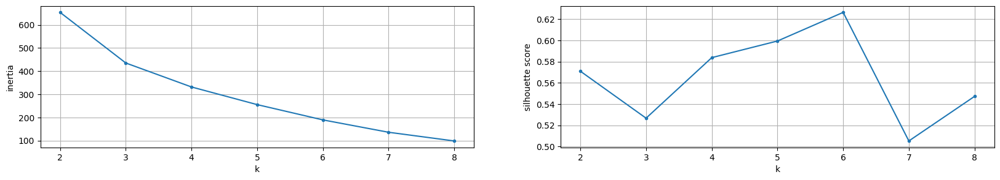

In [126]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_6 = []
silh_6 = []
k_s_6 = np.arange(2, min(9, len(Z_buffer_6)))
for k in k_s_6:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_6)
    inertia_6.append(km_model_aux.inertia_)
    silh_6.append(silhouette_score(Z_buffer_6, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_6, inertia_6, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_6, silh_6, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [127]:
K_NEW_6 = 6   # adjust after looking at the plots above
km_model_buffer_6 = KMeans(n_clusters=K_NEW_6, random_state=9972, n_init=10).fit(Z_buffer_6)

clustering_data_buffer_6 = pd.DataFrame(Z_buffer_6, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_6['labels'] = km_model_buffer_6.labels_
clustering_data_buffer_6[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,65
1,8
2,9
3,3
4,10
5,2


#### Promote the new groups

In [128]:
MIN_MIEMBROS_6 = 5   # adjust according to the size of the groups above

n_original_6 = len(centroides_expandidos_5)
promover_6 = []

for k in range(km_model_buffer_6.n_clusters):
    n = (km_model_buffer_6.labels_ == k).sum()
    if n >= MIN_MIEMBROS_6:
        promover_6.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_6 + len(promover_6) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_6 = {k: n_original_6 + i for i, k in enumerate(promover_6)}
print("Mapeo buffer → global:", mapping_6)

✓ Buffer 0 (65 miembros) → será Cluster 29
✓ Buffer 1 (8 miembros) → será Cluster 30
✓ Buffer 2 (9 miembros) → será Cluster 31
✗ Buffer 3 (3 miembros) → descartado, queda como anomalía
✓ Buffer 4 (10 miembros) → será Cluster 32
✗ Buffer 5 (2 miembros) → descartado, queda como anomalía
Mapeo buffer → global: {0: 29, 1: 30, 2: 31, 4: 32}


In [129]:
nuevos_centroides_6 = km_model_buffer_6.cluster_centers_[promover_6]

centroides_expandidos_6 = np.vstack([centroides_expandidos_5, nuevos_centroides_6])
print(f"Centroides: {n_original_6} → {len(centroides_expandidos_6)}")

buffer_labels_globales_6 = np.array([mapping_6.get(lbl, -1) for lbl in km_model_buffer_6.labels_])
buffer_6['labels_nuevo'] = buffer_labels_globales_6
print(pd.Series(buffer_labels_globales_6).value_counts().sort_index())

Centroides: 29 → 33
-1      5
 29    65
 30     8
 31     9
 32    10
Name: count, dtype: int64


#### Changing the labels (between the previous cut and the new cut)

In [130]:
past_data_df_6 = post_df_5[(ts_post_5 < cut_day_6).to_numpy()].copy()

# Initialize with the labels of the previous final model
past_data_df_6['labels_final'] = past_data_df_6['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_6 = buffer_6[buffer_6.index.isin(past_data_df_6.index)]
past_data_df_6.loc[buf_period_6.index, 'labels_final'] = buf_period_6['labels_nuevo']

# Tag the points that still are outliers
past_data_df_6['outliers_final'] = past_data_df_6['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_6['outliers'].sum()}")
print(f"Outliers después: {past_data_df_6['outliers_final'].sum()}\n")
print(past_data_df_6['labels_final'].value_counts().sort_index())

Outliers antes:   60
Outliers después: 0

labels_final
0     4629
1      263
2      983
4      222
5        4
6     1845
7        2
8     4775
9       10
11    2882
12     345
13      50
14       1
15       5
16     313
18     514
19      38
20    2194
21     105
23    6006
24       1
25     163
26     448
27      20
28       5
29      58
30       2
Name: count, dtype: int64


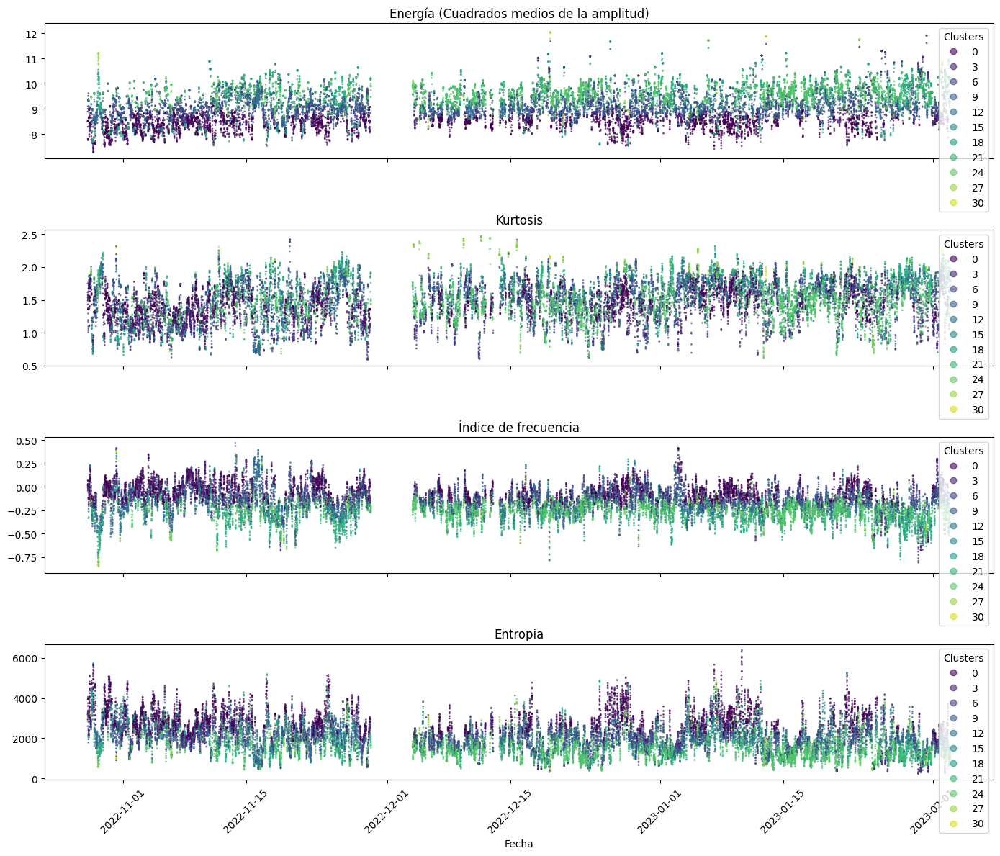

In [131]:
n_cl = len(centroides_expandidos_6)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_6['timestamp'], past_data_df_6[col], c=past_data_df_6['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [132]:
mask_post_6 = (ts_post_5 >= cut_day_6).to_numpy()
post_df_6 = post_df_5[mask_post_6][['timestamp'] + feature_cols].copy()
Z_post_6 = Z_post_5[mask_post_6]

print(f"Observations after {cut_day_6.date()}: {len(post_df_6)}")

dist_post_6 = pairwise_distances(Z_post_6, centroides_expandidos_6)
post_df_6['labels'] = dist_post_6.argmin(axis=1)
post_df_6['distance_to_centroid'] = dist_post_6.min(axis=1)
print(post_df_6['labels'].value_counts().sort_index())

Observations after 2023-02-03: 129208
labels
0     10898
1      1473
2     12539
3        63
4     15920
5        71
6      8840
7       655
8     19592
9        64
10       25
11     1310
12    11373
13     2146
14      358
15        6
16     2647
17       62
18     3084
19      438
20     4784
21       87
22        8
23    25315
24      319
25     1048
26      583
27      746
28      823
29     2905
30       84
31      651
32      291
Name: count, dtype: int64


Outlier bound for iteration 6: computed with the distances of **all the data before the cut day**, scored with the new model.

In [133]:
N_IQR = 1.5   # same multiplier as in the previous iterations

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_6 = clustering_data_all[(ts_all < cut_day_6).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_6 = pca.transform(scaler.transform(past_all_6[feature_cols].to_numpy()))
dist_past_6 = pairwise_distances(Z_past_6, centroides_expandidos_6)
past_all_6['labels'] = dist_past_6.argmin(axis=1)
past_all_6['distance_to_centroid'] = dist_past_6.min(axis=1)

Q1 = past_all_6['distance_to_centroid'].quantile(0.25)
Q3 = past_all_6['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_6 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_6:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_6['outliers'] = past_all_6['distance_to_centroid'] > upper_increment_6
post_df_6['outliers'] = post_df_6['distance_to_centroid'] > upper_increment_6

print(f"Outliers in the past: {past_all_6['outliers'].sum()} ({100*past_all_6['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_6['outliers'].sum()} ({100*post_df_6['outliers'].mean():.2f}%)")

Q1: 0.928 | Q3: 1.423 | IQR: 0.495
Cota superior (Q3 + 1.5*IQR): 2.165
Outliers in the past: 14 (0.01%)
Outliers in the new data: 14010 (10.84%)


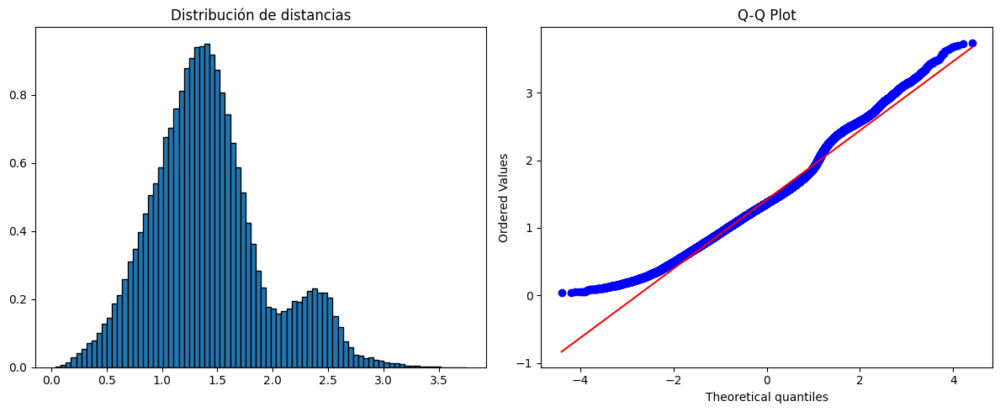

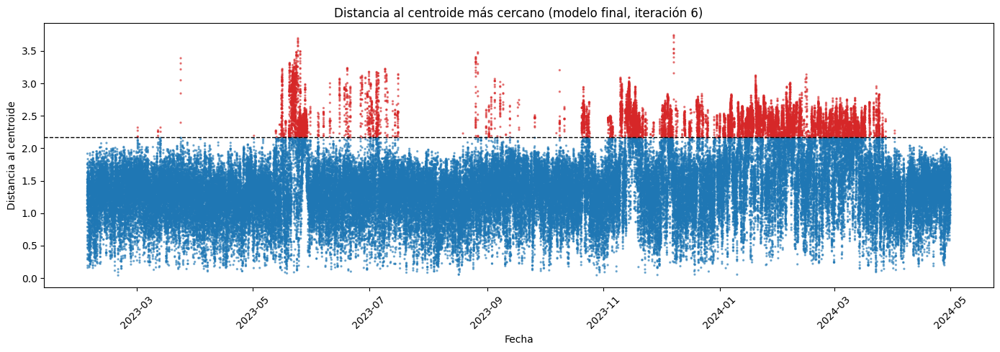

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_6['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_6['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_6['timestamp'], post_df_6['distance_to_centroid'],
            c=post_df_6['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_6, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 6)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [135]:
# The buffer of the next iteration needs the date of the past points
past_all_6['date'] = pd.to_datetime(past_all_6['timestamp']).dt.date
post_df_6['date'] = pd.to_datetime(post_df_6['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_6 = outliers_by_day_5[pd.to_datetime(outliers_by_day_5['date']) < cut_day_6][['date', 'outliers', 'total']]
else:
    gh = past_all_6.groupby('date')['outliers']
    hist_6 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_6.groupby('date')['outliers']
new_6 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_6 = pd.concat([hist_6, new_6]).reset_index(drop=True)
outliers_by_day_6['outliers_pct'] = 100 * outliers_by_day_6['outliers'] / outliers_by_day_6['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_6['mean_window'] = outliers_by_day_6['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_6['std_window'] = outliers_by_day_6['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_6['threshold'] = outliers_by_day_6['mean_window'] + n_std*outliers_by_day_6['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_6['retrain'] = (
    (outliers_by_day_6['outliers'] > outliers_by_day_6['threshold']) &
    (outliers_by_day_6['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_6['date']) >= pd.Timestamp(cut_day_6))
)

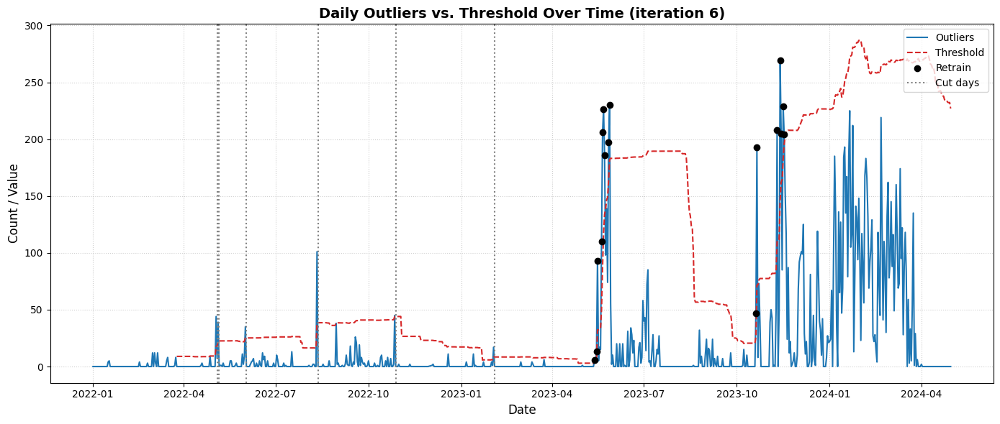

In [136]:
plt.figure(figsize=(14, 6))

dates_6 = pd.to_datetime(outliers_by_day_6['date'])
plt.plot(dates_6, outliers_by_day_6["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_6, outliers_by_day_6["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_6 = outliers_by_day_6[outliers_by_day_6['retrain']]
plt.scatter(pd.to_datetime(flagged_6['date']), flagged_6['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2, cut_day_3, cut_day_4, cut_day_5, cut_day_6]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 6)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [137]:
outliers_by_day_6[outliers_by_day_6['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
493,2023-05-13,6,287,2.090592,0.273810,1.112375,3.610934,True
495,2023-05-15,13,287,4.529617,0.464286,1.799909,5.864013,True
496,2023-05-16,93,287,32.404181,1.571429,10.254926,32.336207,True
500,2023-05-20,110,287,38.327526,3.321429,15.772601,50.639233,True
501,2023-05-21,206,287,71.777003,5.773810,27.156552,87.243467,True
502,2023-05-22,226,287,78.745645,8.464286,36.250283,117.215136,True
503,2023-05-23,186,287,64.808362,10.678571,41.085324,133.934544,True
507,2023-05-27,197,287,68.641115,16.678571,49.027939,163.762389,True
508,2023-05-28,230,287,80.139373,19.416667,54.231589,182.111434,True
653,2023-10-20,47,287,16.376307,2.928571,7.765828,26.226056,True


In [138]:
next_cut_6 = outliers_by_day_6.loc[outliers_by_day_6['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_6}")

Next retraining day: 2023-05-13


## Iteration 7 – retrain at `next_cut_6`

#### Buffer: outliers of all the past (previous model and bound) up to the new cut day

In [139]:
if pd.isna(next_cut_6):
    raise ValueError("next_cut_6 is empty: the previous iteration found no retraining day")

# Same logic as before: the trigger day is included in the buffer
cut_day_7 = pd.Timestamp(next_cut_6) + pd.Timedelta(days=1)
ts_post_6 = pd.to_datetime(post_df_6['timestamp'])

# Outliers of ALL the past according to the previous model and its bound (upper_increment_6):
# (a) before the previous cut (already scored in past_all_6)
mask_old_7 = past_all_6['outliers'].to_numpy()
# (b) between the previous cut and the new cut day
mask_new_7 = ((ts_post_6 < cut_day_7) & post_df_6['outliers']).to_numpy()

cols_buffer = ['timestamp'] + feature_cols + ['date']
buffer_7 = pd.concat([past_all_6[mask_old_7][cols_buffer], post_df_6[mask_new_7][cols_buffer]]).copy()
Z_buffer_7 = np.vstack([Z_past_6[mask_old_7], Z_post_6[mask_new_7]])    # already scaled + PCA

print(f"Outliers en buffer 7: {len(buffer_7)}  (antes del corte anterior: {mask_old_7.sum()} | entre cortes: {mask_new_7.sum()})")
print(buffer_7.groupby('date').size())

Outliers en buffer 7: 37  (antes del corte anterior: 14 | entre cortes: 23)
date
2022-03-06    2
2022-09-05    1
2022-09-19    3
2022-09-22    2
2022-09-24    2
2022-10-27    1
2022-12-03    1
2022-12-04    2
2023-03-01    4
2023-03-12    4
2023-03-13    2
2023-03-24    6
2023-05-01    1
2023-05-13    6
dtype: int64


In [140]:
c_buffer = Z_buffer_7.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_7 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    37.000000
mean      3.372596
std       1.598335
min       1.833154
25%       2.445543
50%       3.088198
75%       3.808917
max       8.927152
dtype: float64


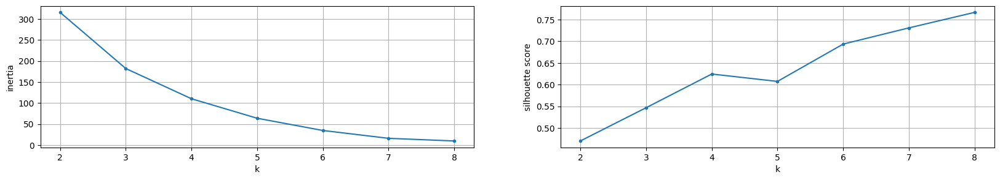

In [141]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_7 = []
silh_7 = []
k_s_7 = np.arange(2, min(9, len(Z_buffer_7)))
for k in k_s_7:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_7)
    inertia_7.append(km_model_aux.inertia_)
    silh_7.append(silhouette_score(Z_buffer_7, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_7, inertia_7, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_7, silh_7, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [142]:
K_NEW_7 = 8   # adjust after looking at the plots above
km_model_buffer_7 = KMeans(n_clusters=K_NEW_7, random_state=9972, n_init=10).fit(Z_buffer_7)

clustering_data_buffer_7 = pd.DataFrame(Z_buffer_7, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_7['labels'] = km_model_buffer_7.labels_
clustering_data_buffer_7[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,12
1,5
2,2
3,6
4,6
5,2
6,2
7,2


#### Promote the new groups

In [143]:
MIN_MIEMBROS_7 = 5   # adjust according to the size of the groups above

n_original_7 = len(centroides_expandidos_6)
promover_7 = []

for k in range(km_model_buffer_7.n_clusters):
    n = (km_model_buffer_7.labels_ == k).sum()
    if n >= MIN_MIEMBROS_7:
        promover_7.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_7 + len(promover_7) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_7 = {k: n_original_7 + i for i, k in enumerate(promover_7)}
print("Mapeo buffer → global:", mapping_7)

✓ Buffer 0 (12 miembros) → será Cluster 33
✓ Buffer 1 (5 miembros) → será Cluster 34
✗ Buffer 2 (2 miembros) → descartado, queda como anomalía
✓ Buffer 3 (6 miembros) → será Cluster 35
✓ Buffer 4 (6 miembros) → será Cluster 36
✗ Buffer 5 (2 miembros) → descartado, queda como anomalía
✗ Buffer 6 (2 miembros) → descartado, queda como anomalía
✗ Buffer 7 (2 miembros) → descartado, queda como anomalía
Mapeo buffer → global: {0: 33, 1: 34, 3: 35, 4: 36}


In [144]:
nuevos_centroides_7 = km_model_buffer_7.cluster_centers_[promover_7]

centroides_expandidos_7 = np.vstack([centroides_expandidos_6, nuevos_centroides_7])
print(f"Centroides: {n_original_7} → {len(centroides_expandidos_7)}")

buffer_labels_globales_7 = np.array([mapping_7.get(lbl, -1) for lbl in km_model_buffer_7.labels_])
buffer_7['labels_nuevo'] = buffer_labels_globales_7
print(pd.Series(buffer_labels_globales_7).value_counts().sort_index())

Centroides: 33 → 37
-1      8
 33    12
 34     5
 35     6
 36     6
Name: count, dtype: int64


#### Changing the labels (between the previous cut and the new cut)

In [145]:
past_data_df_7 = post_df_6[(ts_post_6 < cut_day_7).to_numpy()].copy()

# Initialize with the labels of the previous final model
past_data_df_7['labels_final'] = past_data_df_7['labels']

# Overwrite only the rows of the buffer using the index
# (the buffer also has older points, outside this period: keep only the ones in the period)
buf_period_7 = buffer_7[buffer_7.index.isin(past_data_df_7.index)]
past_data_df_7.loc[buf_period_7.index, 'labels_final'] = buf_period_7['labels_nuevo']

# Tag the points that still are outliers
past_data_df_7['outliers_final'] = past_data_df_7['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_7['outliers'].sum()}")
print(f"Outliers después: {past_data_df_7['outliers_final'].sum()}\n")
print(past_data_df_7['labels_final'].value_counts().sort_index())

Outliers antes:   23
Outliers después: 0

labels_final
0     1287
1       13
2      667
4     2720
6     1113
8     5836
11     400
12     673
13      32
16    1071
18     123
20    3058
21       1
23    8804
25     140
26      41
27      92
28       7
29    2328
30      14
32     138
33      11
35       6
36       6
Name: count, dtype: int64


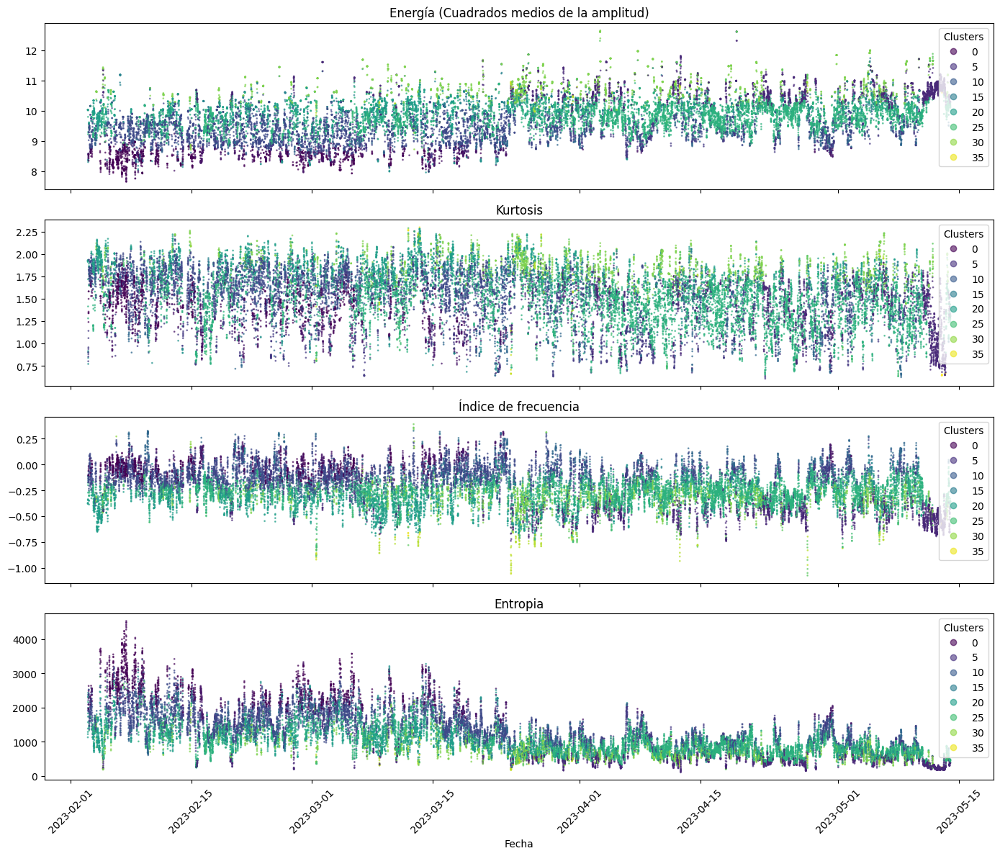

In [146]:
n_cl = len(centroides_expandidos_7)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_7['timestamp'], past_data_df_7[col], c=past_data_df_7['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [147]:
mask_post_7 = (ts_post_6 >= cut_day_7).to_numpy()
post_df_7 = post_df_6[mask_post_7][['timestamp'] + feature_cols].copy()
Z_post_7 = Z_post_6[mask_post_7]

print(f"Observations after {cut_day_7.date()}: {len(post_df_7)}")

dist_post_7 = pairwise_distances(Z_post_7, centroides_expandidos_7)
post_df_7['labels'] = dist_post_7.argmin(axis=1)
post_df_7['distance_to_centroid'] = dist_post_7.min(axis=1)
print(post_df_7['labels'].value_counts().sort_index())

Observations after 2023-05-14: 100627
labels
0      9611
1      1460
2     11872
3        63
4      3021
5        71
6      7459
7       655
8     13616
9        64
10       25
11      910
12    10700
13     2114
14      358
15        6
16     1555
17       62
18     2961
19      438
20     1544
21       86
22        8
23    12563
24      319
25      193
26      534
27      344
28      816
29      522
30       70
31      309
32      111
33      942
34      379
35       61
36    14805
Name: count, dtype: int64


Outlier bound for iteration 7: computed with the distances of **all the data before the cut day**, scored with the new model.

In [148]:
N_IQR = 1.5   # same multiplier as in the previous iterations

# Everything before the new cut day, scored with the NEW model
ts_all = pd.to_datetime(clustering_data_all['timestamp'])
past_all_7 = clustering_data_all[(ts_all < cut_day_7).to_numpy()][['timestamp'] + feature_cols].copy()

Z_past_7 = pca.transform(scaler.transform(past_all_7[feature_cols].to_numpy()))
dist_past_7 = pairwise_distances(Z_past_7, centroides_expandidos_7)
past_all_7['labels'] = dist_past_7.argmin(axis=1)
past_all_7['distance_to_centroid'] = dist_past_7.min(axis=1)

Q1 = past_all_7['distance_to_centroid'].quantile(0.25)
Q3 = past_all_7['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_7 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_7:.3f}")

# The bound comes from the past only, and is applied to both the past and the new data
past_all_7['outliers'] = past_all_7['distance_to_centroid'] > upper_increment_7
post_df_7['outliers'] = post_df_7['distance_to_centroid'] > upper_increment_7

print(f"Outliers in the past: {past_all_7['outliers'].sum()} ({100*past_all_7['outliers'].mean():.2f}%)")
print(f"Outliers in the new data: {post_df_7['outliers'].sum()} ({100*post_df_7['outliers'].mean():.2f}%)")

Q1: 0.937 | Q3: 1.422 | IQR: 0.485
Cota superior (Q3 + 1.5*IQR): 2.150
Outliers in the past: 8 (0.01%)
Outliers in the new data: 5150 (5.12%)


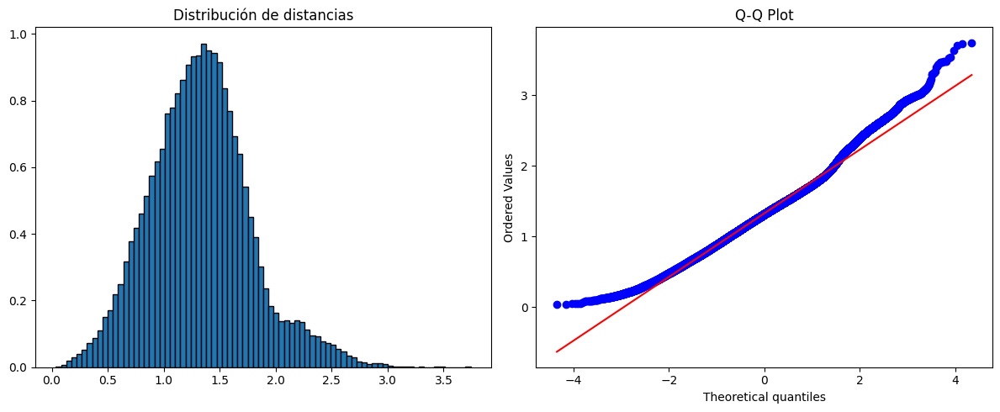

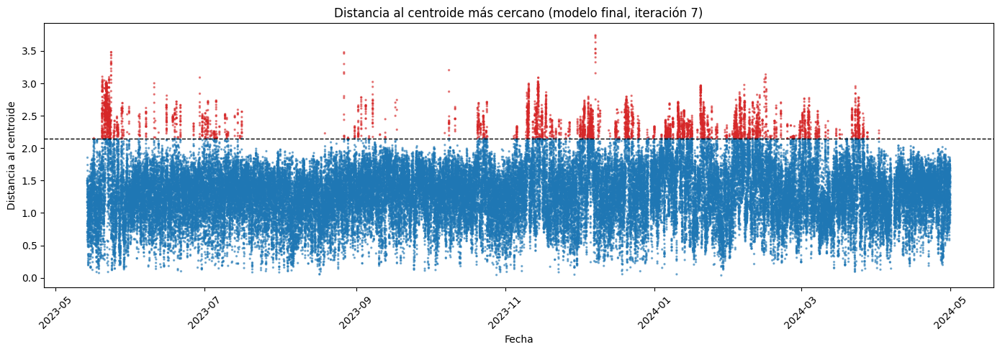

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_7['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_7['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_7['timestamp'], post_df_7['distance_to_centroid'],
            c=post_df_7['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_7, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 7)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [150]:
# The buffer of the next iteration needs the date of the past points
past_all_7['date'] = pd.to_datetime(past_all_7['timestamp']).dt.date
post_df_7['date'] = pd.to_datetime(post_df_7['timestamp']).dt.date

# History before the cut day (HISTORY_MODE is defined in iteration 1)
if HISTORY_MODE == "observed":
    # daily counts as they were seen at the time: chain of the previous iterations
    hist_7 = outliers_by_day_6[pd.to_datetime(outliers_by_day_6['date']) < cut_day_7][['date', 'outliers', 'total']]
else:
    gh = past_all_7.groupby('date')['outliers']
    hist_7 = pd.DataFrame({'outliers': gh.sum().astype(int), 'total': gh.size()}).reset_index()

# New period
g = post_df_7.groupby('date')['outliers']
new_7 = pd.DataFrame({'outliers': g.sum().astype(int), 'total': g.size()}).reset_index()

# History + new period: the rolling window is full from the first day after the cut
outliers_by_day_7 = pd.concat([hist_7, new_7]).reset_index(drop=True)
outliers_by_day_7['outliers_pct'] = 100 * outliers_by_day_7['outliers'] / outliers_by_day_7['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY)
outliers_by_day_7['mean_window'] = outliers_by_day_7['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_7['std_window'] = outliers_by_day_7['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_7['threshold'] = outliers_by_day_7['mean_window'] + n_std*outliers_by_day_7['std_window']

# Only the days after the cut day can trigger the next retraining
outliers_by_day_7['retrain'] = (
    (outliers_by_day_7['outliers'] > outliers_by_day_7['threshold']) &
    (outliers_by_day_7['outliers'] >= MIN_OUTLIERS_DAY) &
    (pd.to_datetime(outliers_by_day_7['date']) >= pd.Timestamp(cut_day_7))
)

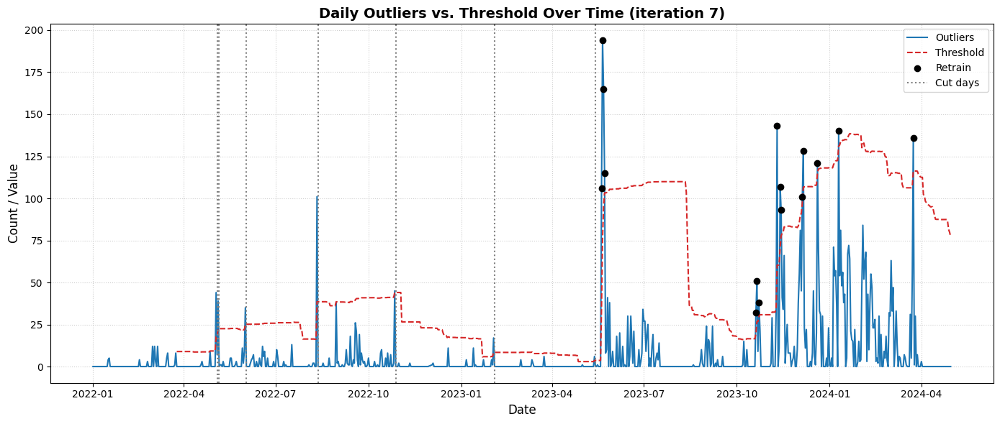

In [151]:
plt.figure(figsize=(14, 6))

dates_7 = pd.to_datetime(outliers_by_day_7['date'])
plt.plot(dates_7, outliers_by_day_7["outliers"],
         label="Outliers", color="#1f77b4", linewidth=1.5)
plt.plot(dates_7, outliers_by_day_7["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_7 = outliers_by_day_7[outliers_by_day_7['retrain']]
plt.scatter(pd.to_datetime(flagged_7['date']), flagged_7['outliers'], color='k', zorder=3, label='Retrain')

for j, c in enumerate([cut_day_1, cut_day_2, cut_day_3, cut_day_4, cut_day_5, cut_day_6, cut_day_7]):
    plt.axvline(pd.Timestamp(c), color='gray', linestyle=':', label='Cut days' if j == 0 else None)

plt.title("Daily Outliers vs. Threshold Over Time (iteration 7)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [153]:
outliers_by_day_7[outliers_by_day_7['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
500,2023-05-20,106,287,36.933798,1.547619,11.587701,36.310722,True
501,2023-05-21,194,287,67.595819,3.857143,23.980988,75.800106,True
502,2023-05-22,165,287,57.491289,5.821429,29.729771,95.010742,True
503,2023-05-23,115,287,40.069686,7.190476,32.018246,103.245215,True
653,2023-10-20,32,287,11.149826,2.130952,5.926822,19.911419,True
654,2023-10-21,51,287,17.770035,2.738095,7.966979,26.639031,True
656,2023-10-23,38,287,13.240418,3.297619,8.855983,29.865567,True
674,2023-11-10,143,287,49.825784,6.011905,18.099121,60.309267,True
677,2023-11-13,107,287,37.282230,7.404762,21.167217,70.906412,True
678,2023-11-14,93,287,32.404181,8.511905,23.117559,77.864582,True


In [154]:
next_cut_7 = outliers_by_day_7.loc[outliers_by_day_7['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_7}")

Next retraining day: 2023-05-20


## Final model applied to all the data

In [155]:
# Final model = the last iteration (change these two lines if you stop earlier)
centroides_final = centroides_expandidos_7
upper_final = upper_increment_7

all_df = clustering_data_all[['timestamp'] + feature_cols].copy()

X_all = scaler.transform(all_df[feature_cols].to_numpy())
Z_all = pca.transform(X_all)

dist_all = pairwise_distances(Z_all, centroides_final)
all_df['labels'] = dist_all.argmin(axis=1)
all_df['distance_to_centroid'] = dist_all.min(axis=1)

print(f"Observations: {len(all_df)}")
print(all_df['labels'].value_counts().sort_index())

Observations: 240015
labels
0     33273
1     17816
2     30609
3       208
4      5519
5       255
6     15101
7      1746
8     27292
9       492
10       59
11     6936
12    13370
13     3900
14     3362
15      698
16     2935
17      310
18     8142
19     3231
20     6792
21      792
22       39
23    29150
24     1721
25      581
26     1401
27      421
28     1166
29     2957
30      228
31      320
32      240
33     1000
34     1952
35      547
36    15454
Name: count, dtype: int64


c:\Users\LENOVO\OneDrive\Documentos\Estancia de Investigación\Estancia_Maestría\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
c:\Users\LENOVO\OneDrive\Documentos\Estancia de Investigación\Estancia_Maestría\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


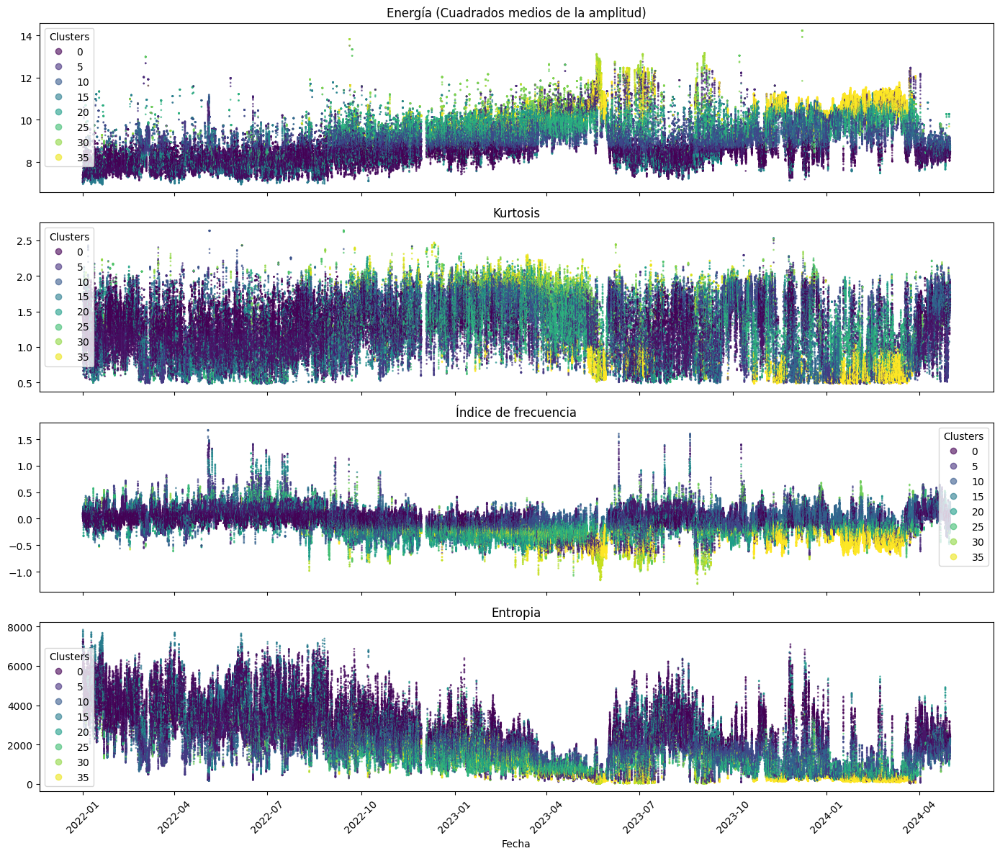

In [156]:
n_cl = len(centroides_final)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(all_df['timestamp'], all_df[col], c=all_df['labels'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

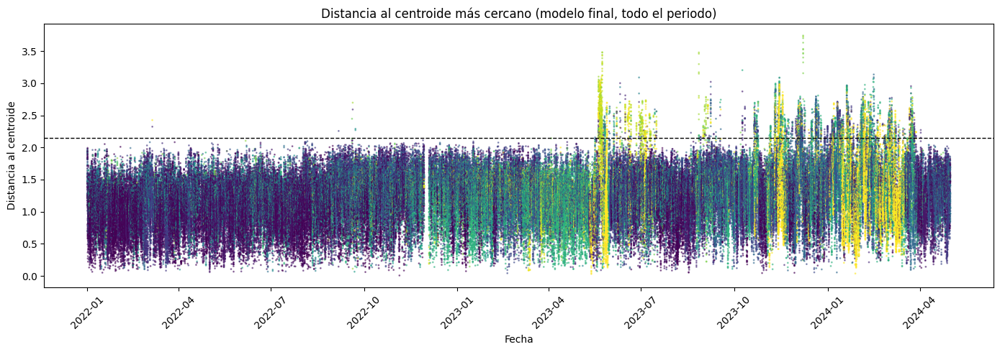

In [157]:
plt.figure(figsize=(14, 5))
plt.scatter(all_df['timestamp'], all_df['distance_to_centroid'], c=all_df['labels'],
            cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.5)
plt.axhline(upper_final, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, todo el periodo)')
plt.xticks(rotation=45)
plt.tight_layout()